<a id="title"></a>
# Quantum Shield level analysis

Circuits, noise, check placement and validation for Flight Schools 1-6 and Main Levels 1-10. Circuit designs and experimental inputs are written explicitly below; searches and simulations run when the notebook executes. The final comparisons check agreement with the game. This notebook revision was developed with AI assistance.

Run from the repository root in the separate analysis environment:

```powershell
python -m venv artifacts/notebook-env
artifacts/notebook-env/Scripts/python.exe -m pip install -r notebooks/requirements.txt
artifacts/notebook-env/Scripts/python.exe scripts/run_notebook.py
```

Use `bin/python` on Linux/macOS. `--check-saved` checks saved execution and source hashes. The finite-family searches run afresh and take several minutes. No cached search result supplies a circuit or score. Results and execution times below come from actual runs.

## Contents

1. [Setup](#setup) and [method](#method)
2. Flight Schools [1](#fs1), [2](#fs2), [3](#fs3), [4](#fs4), [5](#fs5), [6](#fs6)
3. Main Levels [1](#main1), [2](#main2), [3](#main3), [4](#main4), [5](#main5), [6](#main6), [7](#main7), [8](#main8), [9](#main9), [10](#main10)
4. [Across levels](#cross-level), [T scorer](#t-validation), [reproduction](#reproducibility)

These are reproducible design reconstructions of the current game, not evidence that this notebook was written before the implementation. No development chronology is implied.


<a id="setup"></a>
## Setup

Write the circuits here, then test them with the shared physics and player-facing validator. Seed 2026 and 1024 shots match validation; pass/fail scores use exact density matrices. Stored fixtures are used only to check the result, not to supply circuit designs.


In [1]:
import os, sys, time, json, inspect, platform, warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend/missions/levels.py").exists())
sys.path.insert(0, str(ROOT))
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"
START = time.perf_counter()
# Keep genuine warnings but omit machine-specific source-file paths.
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, JSON, Code
from qiskit import QuantumCircuit
from qiskit.quantum_info import Pauli
from backend.quantum_core.pauli import opening_factor, propagate
from backend.quantum_core.checks import closing_factors
from backend.quantum_core.scoring import exact_density, ideal_reference, accepted_metrics, trusted_fidelity
from backend.quantum_core.paulice import optimize_clifford
from backend.missions.simulation import execution_schedule, simulate
from backend.missions.reference import optimize
from backend.missions.reference import shell, empty
from scripts.run_notebook import analysis_inputs
from scripts import level_design_analysis as lab
from scripts.level_design_analysis import table
SEED, SHOTS = 2026, 1024
SEARCHES = []
SUMMARY, STRATEGY_ROWS = [], {}
plt.rcParams.update({"font.size":9, "figure.dpi":85})
table([dict(seed=SEED, shots=SHOTS, search="fresh exact finite-family enumeration")])

def search_now(number):
    started = time.perf_counter()
    result = optimize(number)
    record = dict(level=number, result=result, seconds=time.perf_counter()-started)
    SEARCHES.append(record)
    return record


seed,shots,search
2026,1024,fresh exact finite-family enumeration


In [2]:
from backend.timeline_lab.service import HOTSPOT, CHECK_STRENGTH
from backend.quantum_core.noise import hardware_items
fs2_hardware = dict(enabled=True, bitFlip=.025, phaseFlip=.01, depolarizing=0,
                    relaxationTimeUs=0, t1Us=100, t2Us=80)
fs6_hardware = dict(enabled=True, bitFlip=.001, phaseFlip=.001, depolarizing=0,
                    relaxationTimeUs=0, t1Us=100, t2Us=80)
mission_hardware = dict(enabled=True, bitFlip=.00015, phaseFlip=.00015,
                       depolarizing=.0002, relaxationTimeUs=0, t1Us=100, t2Us=200)
table([dict(experiment="FS2", hardware=fs2_hardware),
       dict(experiment="FS6", hardware=fs6_hardware),
       dict(experiment="Main missions", hardware=mission_hardware)])
print("Synthetic independent channels after occupied layers on all live wires, including check and T gates.")
print("FS6 hotspot and check cost:", HOTSPOT, CHECK_STRENGTH)
print("Native Paulice experiments separately use NoiseModel(gate_noise=.01, readout_noise=0).")


experiment,hardware
FS2,"{""enabled"": true, ""bitFlip"": 0.025, ""phaseFlip"": 0.01, ""depolarizing"": 0, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 80}"
FS6,"{""enabled"": true, ""bitFlip"": 0.001, ""phaseFlip"": 0.001, ""depolarizing"": 0, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 80}"
Main missions,"{""enabled"": true, ""bitFlip"": 0.00015, ""phaseFlip"": 0.00015, ""depolarizing"": 0.0002, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 200}"


Synthetic independent channels after occupied layers on all live wires, including check and T gates.
FS6 hotspot and check cost: {'channel': 'decoherence', 'timeUs': 70.0, 't1Us': 100.0, 't2Us': 200.0} 0.02
Native Paulice experiments separately use NoiseModel(gate_noise=.01, readout_noise=0).


<a id="method"></a>
## 2. Method recap

An ancilla H, controlled opening P, payload interval U, controlled inverse closing P′, H and measurement form the check. The ideal relation is P′U=UP; signed/ordered products require phase compensation. The real validator checks the full input isometry, not just one input state. Dynamic window selection and generated closings stay in the real mission service.

Cliffords transport a Pauli to one signed Pauli. T/Tdg reject X/Y support at a crossing; I/Z commute. The noisy scorer for **all** missions is exact Aer density-matrix evolution; the ideal projector uses stabilizers for Clifford payloads and a statevector for T payloads. For the all-zero-syndrome block B: kept yield is Tr(B), postselected fidelity is Tr(rho_ideal B)/Tr(B), and correct_shot_yield is their product. The game score is Trusted Fidelity: F_ps · min(1, S_keep/S_min). It equals kept-shot fidelity above the explicit budget and applies a retention penalty below it. This is a game design choice and a simulation-only full-state quantity, not a hardware-count fidelity estimator. F_ps and S_keep are always reported together. No finite-shot fluctuation decides a pass.


In [3]:
demo=[]
for gate, axis in [("h","X"),("s","X"),("sdg","X"),("t","Z"),("t","X"),("tdg","Y")]:
    try:
        frame=propagate(opening_factor(1,0,axis),gate,[0],1)
        demo.append(dict(gate=gate, opening=axis, transported=frame.to_label(), status="single Pauli"))
    except ValueError as error:
        demo.append(dict(gate=gate, opening=axis, transported=None, status=str(error)))
table(demo)
frame=propagate(opening_factor(1,0,"X"),"sdg",[0],1)
print("Actual inverse-closing factors, including relative phase:",closing_factors(frame.to_matrix(),1))
print("Single-qubit transport and signed inverse closures above use the actual core functions.")


gate,opening,transported,status
h,X,Z,single Pauli
s,X,Y,single Pauli
sdg,X,-Y,single Pauli
t,Z,Z,single Pauli
t,X,—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.
tdg,Y,—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.


Actual inverse-closing factors, including relative phase: [('cy', [1, 0]), ('z', [1])]
Single-qubit transport and signed inverse closures above use the actual core functions.


Targets were calibrated by the existing script and are not re-tuned in this notebook. The exact source excerpt below documents the main-level budget/target safety assertions; FS6 uses the target returned by its own evaluator. “Optimal” throughout means **best in the declared finite search family**, not a global optimum over arbitrary multi-helper circuits. Native Paulice gamma suggestions are a different objective and are never used as T-level scores or optima.

All current bounded-family winning references fall below their calibrated shot budget. Their scores are therefore scaled correct-shot yields; the saturation branch is implemented and tested but is not reached by these winners. Reoptimization does not imply that every winning placement changed. No payload or noise parameter was changed.


In [4]:
from scripts.validate_main_levels import assert_target_validity
display(Code(inspect.getsource(assert_target_validity), language="python"))
print("Target safety is checked after constructing and scoring each design; no target is fitted to these outputs.")


def assert_target_validity(row,metrics):
    t=row['target'];b=row['minimumKept']
    assert metrics['baseline']['fidelity']<t, 'Baseline must fail on fidelity itself.'
    assert row['baseline']<=t-.05 and row['everywhere']<=t-.05
    assert row['reasonable']>=t+.03 and row['optimal']>row['reasonable']
    assert row['optimal']>=t+.05, 'The stored winner must reach the existing third-star threshold.'
    assert row['misplaced']<t
    assert .60<=(t-row['baseline'])/(row['optimal']-row['baseline'])<=.80
    # Retention contributes a real penalty; fidelity can also contribute.
    assert metrics['everywhere']['retention']<b
    assert row['everywhere']<metrics['everywhere']['fidelity']
    assert row['everywhere']<row['reasonable']

Target safety is checked after constructing and scoring each design; no target is fitted to these outputs.


<a id="fs1"></a>
## 3.1. Flight School 1 — Quantum errors

The explicit X-error experiment and additional allowed phase/decoherence experiments use the actual FS1 run function. The extra waiting times are experimental inputs, not authored changes to a level. Compare exact probabilities with seeded counts; phase-flipped plus/minus states can agree in Z but disagree in X. This lesson completes by experiment and MCQs, not a score threshold.


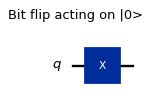

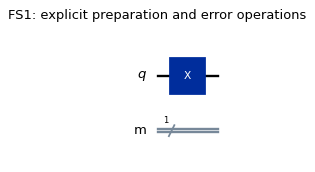

experiment,basis,fidelity,idealProbabilities,noisyProbabilities,counts
explicit X error,Z,0,"{""0"": 1.0, ""1"": 0.0}","{""0"": 0.0, ""1"": 1.0}","{""0"": 0, ""1"": 1024}"
Z error on plus / Z readout,Z,3.14018e-16,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 474, ""1"": 550}"
Z error on plus / X readout,X,3.14018e-16,"{""0"": 0.9999999999999997, ""1"": 0.0}","{""0"": 0.0, ""1"": 0.9999999999999997}","{""0"": 0, ""1"": 1024}"
"wait 0 us (T1=100, T2=80)",Z,1,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 474, ""1"": 550}"
"wait 20 us (T1=100, T2=80)",Z,0.8894,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.5906346234610089, ""1"": 0.4093653765389908}","{""0"": 573, ""1"": 451}"
"wait 60 us (T1=100, T2=80)",Z,0.736183,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.7255941819529865, ""1"": 0.2744058180470132}","{""0"": 718, ""1"": 306}"
"wait 120 us (T1=100, T2=80)",Z,0.611565,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.8494028940438987, ""1"": 0.15059710595610107}","{""0"": 858, ""1"": 166}"


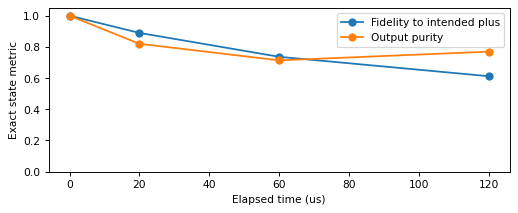

In [5]:
# |0> followed by one X fault: no state-preparation gate is needed.
fs1 = QuantumCircuit(1)
fs1.x(0)
lab.draw(fs1, "Bit flip acting on |0>")
fs1_request = dict(circuit=dict(qubits=1, operations=[
    dict(id="fault", role="error", name="bit_flip", qubits=[0], column=0)]),
    basis="Z", shots=SHOTS, sampleSeed=SEED)
SUMMARY.append(lab.noise_school(fs1_request))


<a id="fs2"></a>
## 3.2. Flight School 2 — Detection, mitigation and correction

Run the same explicit hardware-noise experiment with noise enabled/disabled for each method. Detection returns a filtered state, mitigation an observable estimate (not a state), and correction a decoded state. The circuit pictures show the actual generated gate/readout/recovery structure; background noise channels are omitted only in drawings. Added noisy gates can make a method worse. Completion requires trying all methods, not maximizing an invented fidelity target.


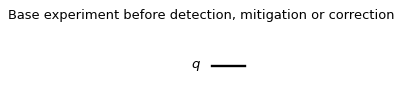

hardware,method,idealE,noisyE,finalE,sampledE,stateFidelity,kept,physicalQubits,methodShots
False,detection,1,1,1,1,1,1,2,1024
False,mitigation,1,1,1,1,—,—,1,3072
False,correction,1,1,1,1,1,1,5,1024
True,detection,1,0.95,0.851598,0.848018,0.925799,0.895408,2,1024
True,mitigation,1,0.95,0.99255,0.98763,—,—,1,3072
True,correction,1,0.95,0.438409,0.439453,0.719204,1,5,1024


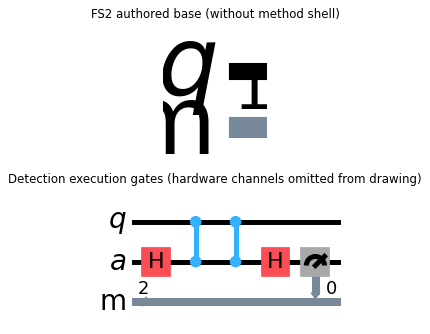

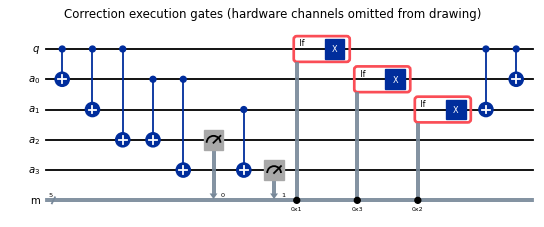

hardware,completion,interpretation
"{""enabled"": true, ""bitFlip"": 0.025, ""phaseFlip"": 0.01, ""depolarizing"": 0, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 80}",Try all three methods on a valid authored circuit.,"Mitigation estimates E, not a repaired quantum state; compare E, not fabricated mitigation state fidelity."


In [6]:
# Start at |0>; the same hardware settings are used for all three methods.
fs2 = QuantumCircuit(1)
lab.draw(fs2, "Base experiment before detection, mitigation or correction")
fs2_experiment = dict(qubits=1, operations=[], hardware=fs2_hardware,
    noise=dict(enabled=True, channel="bit_flip", targetQubit=0, boundary=0, probability=.15))
SUMMARY.append(lab.protection_school(dict(experiment=fs2_experiment,
    methods=["detection", "mitigation", "correction"], qubits=1,
    criteria="Try all three methods on a valid authored circuit.")))


<a id="fs3"></a>
## 3.3. Flight School 3 — Coherent Pauli checks across S

The guided S payload transports the chosen opening through the shared core step by step. The full validator certifies the reference; a changed closing gate is invalid. The explicit injected fault and a fault-free variant demonstrate that a green ideal identity can still flag real noise. Completion also needs the existing knowledge check.


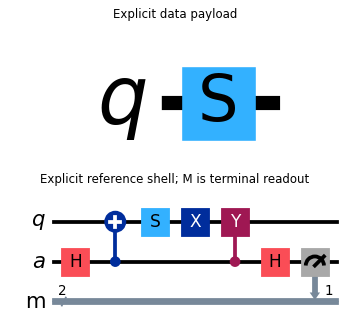

step,operator,status
Opening,X,Pauli
S[0],Y,Pauli


case,valid,connector,nonPauli,syndromeCounts,explanation
explicit reference,True,GREEN,False,"{""1"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
without explicit fault,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
incorrect CX check,False,RED,False,—,Closing product or sign does not match U P U†.


In [7]:
fs3 = QuantumCircuit(1)
fs3.s(0)
# Ancilla H, opening CPs, optional fault, closing CPs, H and M.
taps = [('h', [1], 0),
 ('cx', [1, 0], 1),
 ('bit_flip', [0], 3),
 ('cy', [1, 0], 4),
 ('h', [1], 5),
 ('m', [1], 6)]
draft = dict(lesson=3, dataQubits=1, ancillas=1, columns=7,
    operations=[dict(id=f"g{i}", name=name, qubits=wires, column=column)
                for i, (name, wires, column) in enumerate(taps)])
SUMMARY.append(lab.check_school(3, fs3, draft))


<a id="fs4"></a>
## 3.4. Flight School 4 — Multi-qubit CNOT propagation

The actual guided H/CX payload transports the chosen opening into a product check. Removing a closing factor gives the contrasting invalid result. A multi-wire match must preserve the complete noiseless input isometry; circuit pictures are drawn by Qiskit. Completion also requires the lesson knowledge answers.


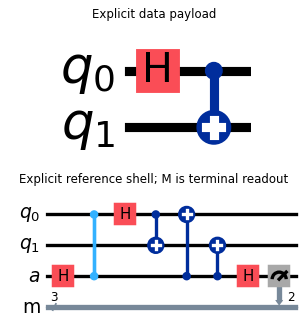

step,operator,status
Opening,IZ,Pauli
H[0],IX,Pauli
"CX[0, 1]",XX,Pauli


case,valid,connector,nonPauli,syndromeCounts,explanation
explicit reference,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
without explicit fault,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
incomplete single-wire closing,False,RED,False,—,Closing product or sign does not match U P U†.


In [8]:
fs4 = QuantumCircuit(2)
fs4.h(0)
fs4.cx(0, 1)
# Ancilla H, opening CPs, optional fault, closing CPs, H and M.
taps = [('h', [2], 0),
 ('cz', [2, 0], 1),
 ('cx', [2, 0], 6),
 ('cx', [2, 1], 7),
 ('h', [2], 8),
 ('m', [2], 9)]
draft = dict(lesson=4, dataQubits=2, ancillas=1, columns=10,
    operations=[dict(id=f"g{i}", name=name, qubits=wires, column=column)
                for i, (name, wires, column) in enumerate(taps)])
SUMMARY.append(lab.check_school(4, fs4, draft))


<a id="fs5"></a>
## 3.5. Flight School 5 — The non-Clifford barrier

The guided T payload accepts the Z shell. X/Y versions are rejected by the real validator before scoring; core propagation explains where a single Pauli is lost. The table is a physical validity test, not an arbitrary gameplay penalty. Completion uses the valid experiment plus its knowledge answer.


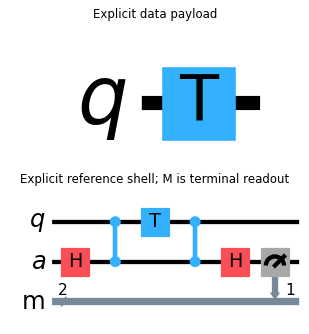

step,operator,status
Opening,Z,Pauli
T[0],Z,Pauli


case,valid,connector,nonPauli,syndromeCounts,explanation
explicit reference,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
without explicit fault,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
incorrect CX check,False,RED,True,—,Non-Pauli transport at T: the check becomes a coherent Pauli sum; a Pauli-only closure is unsupported.
incorrect CY check,False,RED,True,—,Non-Pauli transport at T: the check becomes a coherent Pauli sum; a Pauli-only closure is unsupported.


step,operator,status
Opening,X,Pauli
T[0],—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.
Opening,Y,Pauli
T[0],—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.


In [9]:
fs5 = QuantumCircuit(1)
fs5.t(0)
# Ancilla H, opening CPs, optional fault, closing CPs, H and M.
taps = [('h', [1], 0), ('cz', [1, 0], 1), ('cz', [1, 0], 4), ('h', [1], 5), ('m', [1], 6)]
draft = dict(lesson=5, dataQubits=1, ancillas=1, columns=7,
    operations=[dict(id=f"g{i}", name=name, qubits=wires, column=column)
                for i, (name, wires, column) in enumerate(taps)])
SUMMARY.append(lab.check_school(5, fs5, draft))


<a id="fs6"></a>
## 3.6. Flight School 6 — Trade-off optimization

The fixed short Clifford payload has two data qubits, one helper and a localized relaxation hotspot. Baseline, blanket, sensible and bounded-best drafts are evaluated repeatedly with the same hardware settings. The target must lie above careless strategies and below a sensible solution. The real native Paulice suggestion is shown separately from the independently enumerated game-score reference.


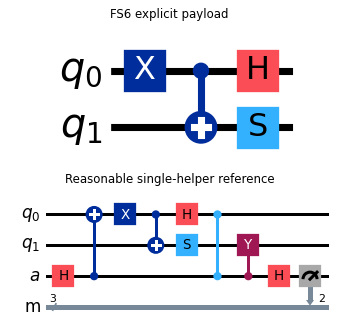

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid
baseline,0.494132,1,0.494132,0.494132,0.99,0.62,0,False
everywhere,0.478589,0.954849,0.461596,0.45698,0.99,0.62,0,True
reasonable,0.816186,0.818607,0.674885,0.668136,0.99,0.62,0,True
optimal,0.827609,0.829038,0.69305,0.686119,0.99,0.62,0,True


strategy,baselineScore,qualificationThreshold,fidelity,retention,score,samplingOverhead,minimumKept,correct_shot_yield,scoreVersion
misplaced,0.494132,0.62,0.48808,0.966928,0.476705,1.0342,0.99,0.471938,trusted-fidelity-v1
tooSmall,0.494132,0.62,0.937114,0.497813,0.47122,2.00879,0.99,0.466508,trusted-fidelity-v1
overchecked,0.494132,0.62,0.900542,0.499208,0.454099,2.00317,0.99,0.449558,trusted-fidelity-v1


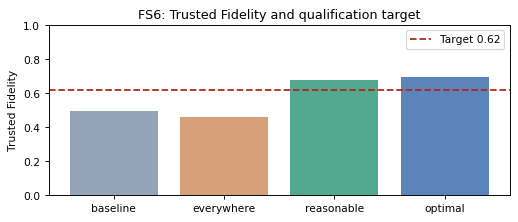

Game reference search: Exact maximum over 15 single-ancilla full-payload Pauli-product shells; fixed tap order and terminal readout. Arbitrary placements and multi-check circuits are outside this certificate. Candidates: 15
Separate native Paulice gamma: 1.0202354230673039 added helpers: 0


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.02024,[],[],0,17


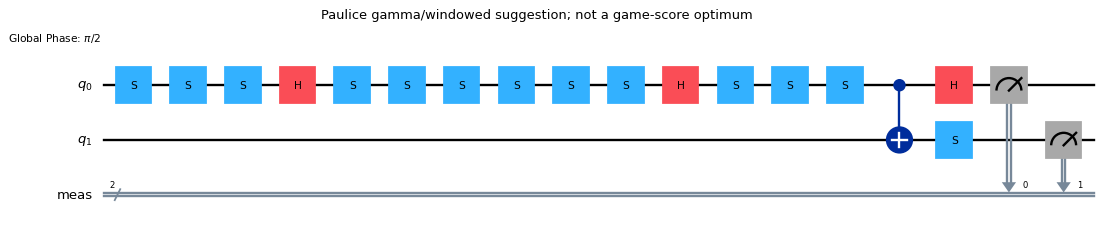

In [10]:
fs6 = QuantumCircuit(2)
fs6.x(0)
fs6.cx(0, 1)
fs6.h(0)
fs6.s(1)
# Explicit shell designs; the best of all 15 Pauli products is searched below.
fs6_taps = {
    "baseline": [],
    "reasonable": [('h', [2], 0), ('cx', [2, 0], 1), ('cz', [2, 0], 9), ('cy', [2, 1], 10), ('h', [2], 13), ('m', [2], 14)],
    "everywhere": [('h', [2], 0), ('cx', [2, 0], 1), ('cx', [2, 1], 2), ('cz', [2, 0], 9), ('h', [2], 13), ('m', [2], 14)],
    "misplaced": [('h', [2], 0), ('cz', [2, 0], 1), ('cx', [2, 0], 9), ('z', [2], 12), ('h', [2], 13), ('m', [2], 14)],
    "tooSmall": [('h', [2], 0), ('cz', [2, 1], 2), ('cx', [2, 0], 9), ('cz', [2, 1], 10), ('h', [2], 13), ('m', [2], 14)],
    "overchecked": [('h', [2], 0), ('cx', [2, 0], 1), ('cy', [2, 1], 2), ('cy', [2, 0], 9), ('cz', [2, 1], 10), ('z', [2], 12), ('h', [2], 13), ('m', [2], 14)],
}
fs6_drafts = {name:dict(lesson=6, dataQubits=2, ancillas=1, columns=15,
    hardware=fs6_hardware, operations=[dict(id=f"g{i}", name=gate, qubits=wires, column=column)
    for i, (gate, wires, column) in enumerate(taps)]) for name,taps in fs6_taps.items()}
SUMMARY.append(lab.capstone(fs6, fs6_drafts))
fs6_paulice = lab.paulice_path(fs6, targets=[1], ancilla_limit=1)


<a id="main1"></a>
## 4.1. Main Level 1

Manual opening/closing on two data wires and one helper. Compare the full-span reasonable check with the best-found interior check. Inserted bands are editable; the payload gates remain fixed.


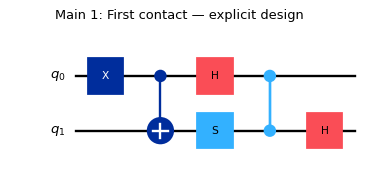

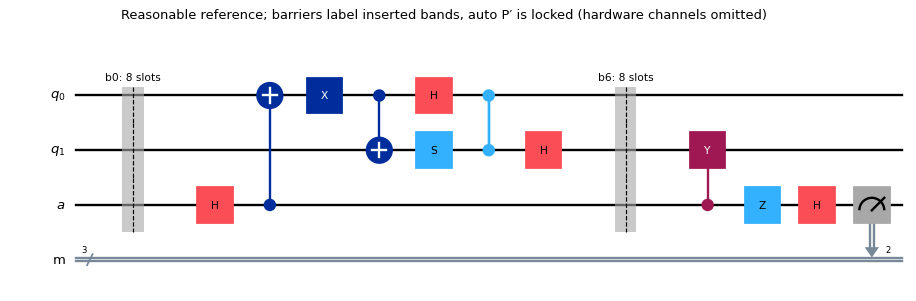

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.466665,1,0.466665,0.466665,0.99,0.63,0,False,False,0,0
everywhere,0.454601,0.958589,0.440177,0.435775,0.99,0.63,0,True,False,1,3
reasonable,0.822369,0.821266,0.682206,0.675384,0.99,0.63,0,True,True,1,2
optimal,0.827453,0.82375,0.6885,0.681615,0.99,0.63,0,True,True,1,2
misplaced,0.459707,0.973652,0.452116,0.447595,0.99,0.63,0,True,False,1,2
tooSmall,0.939735,0.470686,0.446788,0.44232,0.99,0.63,0,True,False,1,3
overchecked,0.813637,0.812578,0.667821,0.661143,0.99,0.63,0,True,True,1,3


Data: 2 Fixed helpers: 1 T/Tdg: 0 Payload gates: 6 Depth: 5
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 1, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 76.0}
Inserted editable bands: {"0": 8, "6": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b0s1", "closing": "b6s1", "valid": true}]
Search: clifford-pauli-reference-search candidates: 75 best opening: XI interval: (1, 2) live search seconds: 2.554
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.04088,[],[],0,19
1,1,1.03741,[0],"[[1, 2]]",1,32


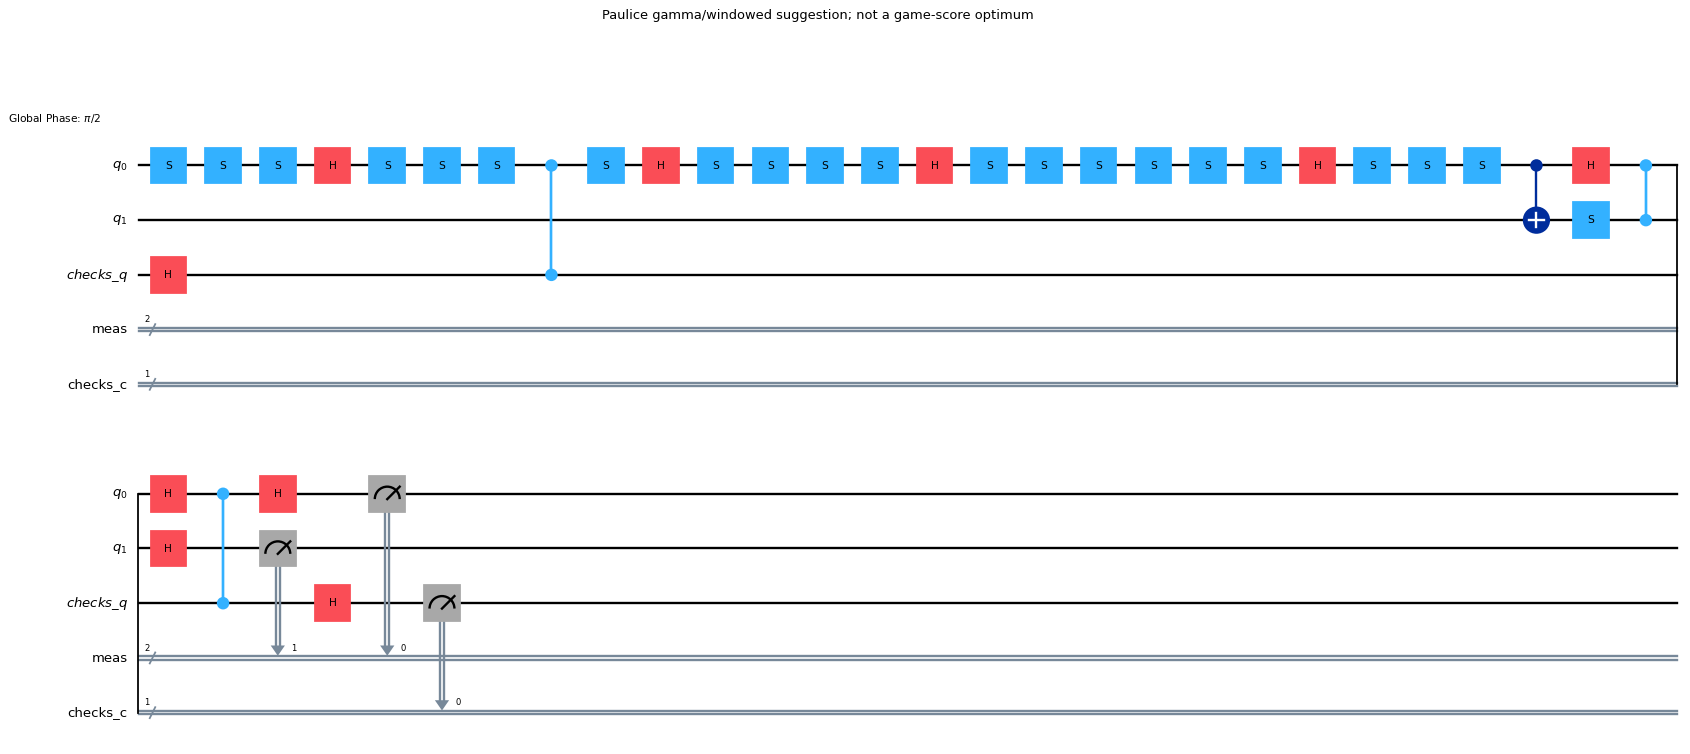

In [11]:
design = QuantumCircuit(2)
design.x(0)
design.cx(0, 1)
design.s(1)
design.h(0)
design.cz(0, 1)
design.h(1)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 1, 0.99, 0.63
hotspot_column, relaxation_us = 1, 76.0
actual = lab.missions.get_level(1)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XX', 0, 6, 1),
 'misplaced': ('IX', 0, 1, 1),
 'overchecked': ('IY', 1, 6, 1),
 'reasonable': ('IX', 0, 6, 1),
 'tooSmall': ('ZI', 1, 2, 1)}
drafts = {name:shell(1, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(1)
search = search_now(1)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[1] = lab.main_level(1, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main2"></a>
## 4.2. Main Level 2

A wider Clifford payload with a single helper tests manual product closure and careful window selection. The shell trials below explicitly specify openings and boundaries and use the real player-reachable check constructor.


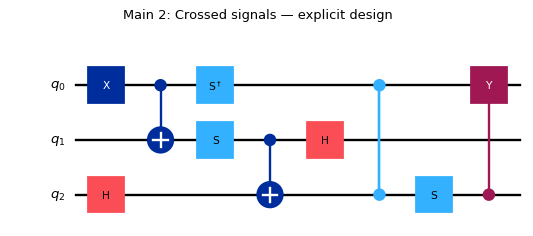

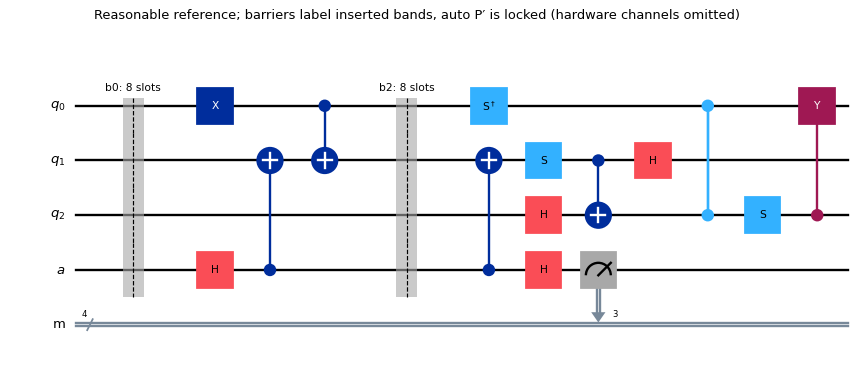

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.455944,1,0.455944,0.455944,0.97,0.64,0,False,False,0,0
everywhere,0.437008,0.92924,0.418645,0.406086,0.97,0.64,0,True,False,1,5
reasonable,0.819311,0.820369,0.692925,0.672137,0.97,0.64,0,True,True,1,2
optimal,0.819429,0.820529,0.69316,0.672365,0.97,0.64,0,True,True,1,2
misplaced,0.448693,0.973652,0.448693,0.436871,0.97,0.64,0,True,False,1,2
tooSmall,0.932589,0.462158,0.444334,0.431004,0.97,0.64,0,True,False,1,3
overchecked,0.801854,0.805776,0.666097,0.646114,0.97,0.64,0,True,True,1,3


Data: 3 Fixed helpers: 1 T/Tdg: 0 Payload gates: 10 Depth: 7
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 1, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 78.0}
Inserted editable bands: {"0": 8, "10": 8, "2": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b0s2", "closing": "b2s1", "valid": true}]
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (1, 2) live search seconds: 10.105
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.08706,[],[],0,14
1,1,1.0584,[0],"[[2, 3]]",1,19


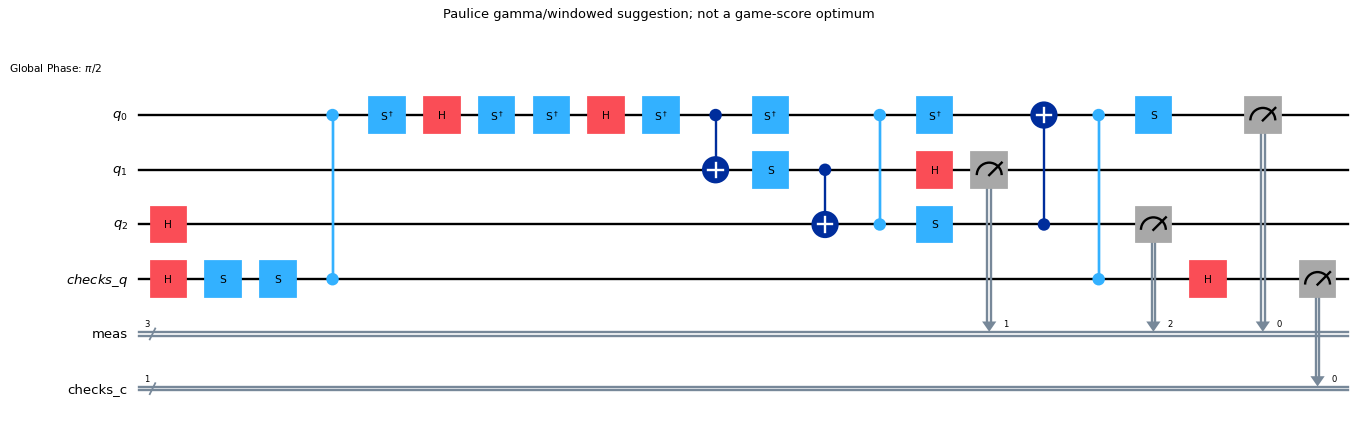

In [12]:
design = QuantumCircuit(3)
design.x(0)
design.cx(0, 1)
design.h(2)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 1, 0.97, 0.64
hotspot_column, relaxation_us = 1, 78.0
actual = lab.missions.get_level(2)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XXX', 0, 10, 1),
 'misplaced': ('IIX', 0, 1, 1),
 'overchecked': ('IIY', 0, 10, 1),
 'reasonable': ('IXI', 0, 2, 1),
 'tooSmall': ('IZI', 1, 2, 1)}
drafts = {name:shell(2, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(2)
search = search_now(2)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[2] = lab.main_level(2, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main3"></a>
## 4.3. Main Level 3

Manual signed closures with a larger helper budget test support spreading and overlapping-check costs. Blanket checks are valid comparison circuits, but their resource/noise overhead can lose.


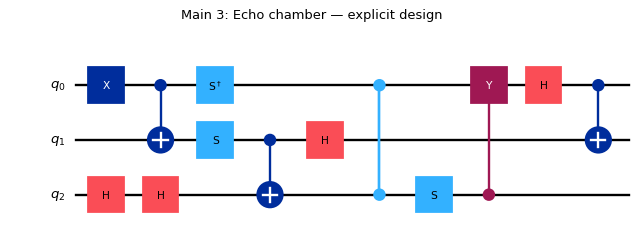

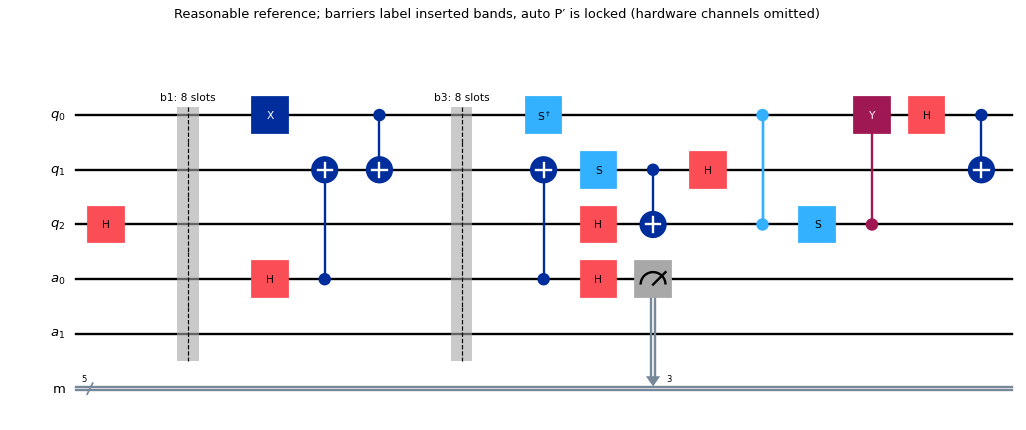

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.445385,1,0.445385,0.445385,0.94,0.65,0,False,False,0,0
everywhere,0.412004,0.815689,0.357518,0.336067,0.94,0.65,0,True,False,2,12
reasonable,0.814416,0.817022,0.707868,0.665396,0.94,0.65,0,True,True,1,2
optimal,0.814533,0.817181,0.708107,0.665621,0.94,0.65,0,True,True,1,2
misplaced,0.438304,0.973652,0.438304,0.426755,0.94,0.65,0,True,False,1,2
tooSmall,0.928823,0.454076,0.448677,0.421756,0.94,0.65,0,True,False,1,3
overchecked,0.799313,0.801283,0.681358,0.640476,0.94,0.65,0,True,True,1,3


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 13 Depth: 9
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 2, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 80.0}
Inserted editable bands: {"0": 4, "1": 8, "13": 8, "3": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b1s2", "closing": "b3s1", "valid": true}]
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (2, 3) live search seconds: 11.351
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.10905,[],[],0,16
1,1,1.07982,[0],[[3]],1,24
2,2,1.07622,"[0, 1]","[[3], [0, 4]]",2,28


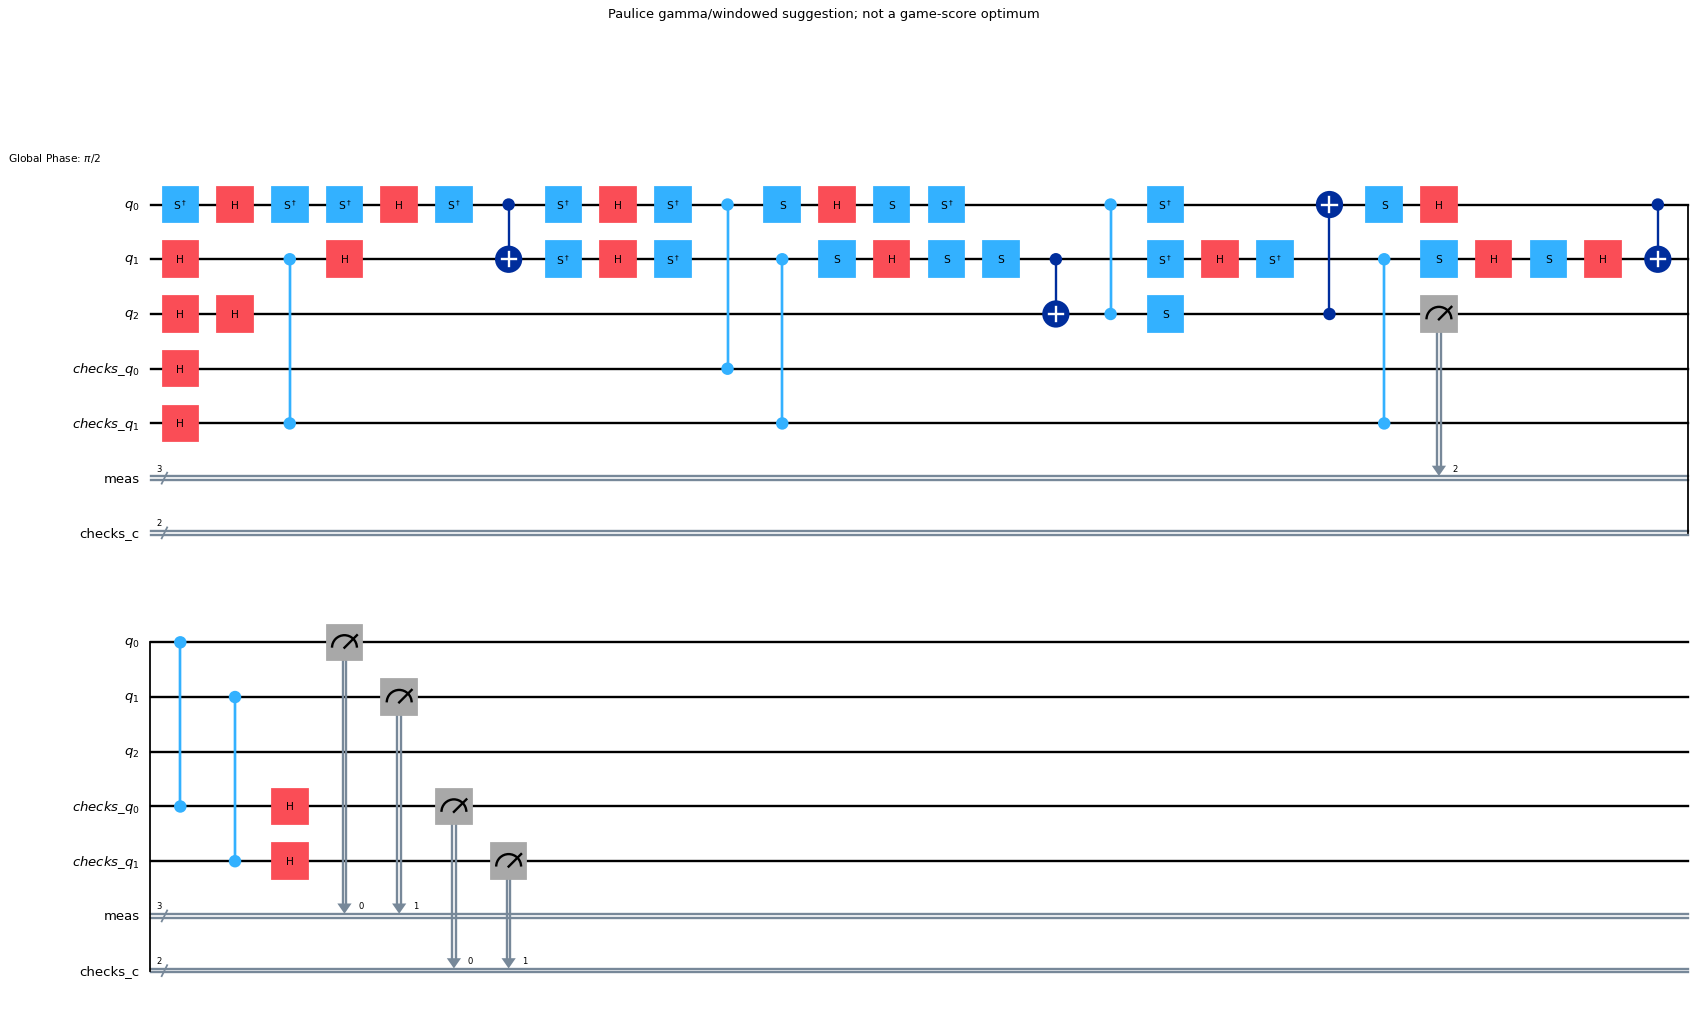

In [13]:
design = QuantumCircuit(3)
design.h(2)
design.x(0)
design.cx(0, 1)
design.h(2)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 2, 0.94, 0.65
hotspot_column, relaxation_us = 2, 80.0
actual = lab.missions.get_level(3)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XXX', 0, 13, 2),
 'misplaced': ('IIX', 0, 1, 1),
 'overchecked': ('XIY', 0, 13, 1),
 'reasonable': ('IXI', 1, 3, 1),
 'tooSmall': ('IZI', 2, 3, 1)}
drafts = {name:shell(3, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(3)
search = search_now(3)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[3] = lab.main_level(3, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main4"></a>
## 4.4. Main Level 4

Assisted P′ is generated by the real validator on the selected interior interval. Generated gates are labeled in the Qiskit image and listed as locked operations below.


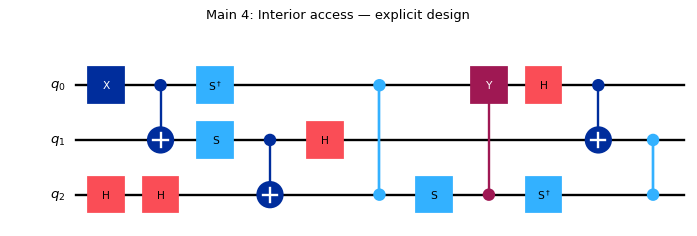

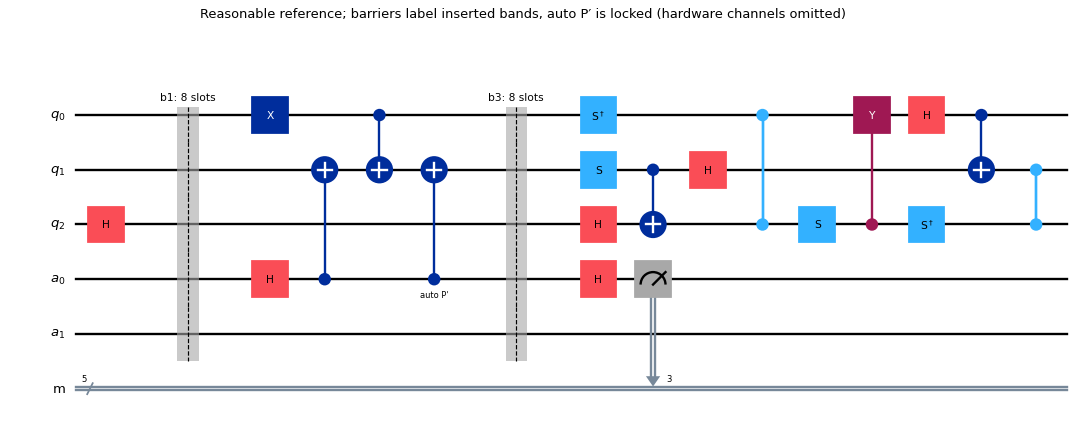

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.436066,1,0.436066,0.436066,0.92,0.66,0,False,False,0,0
everywhere,0.407866,0.813798,0.360783,0.331921,0.92,0.66,0,True,False,2,12
reasonable,0.810022,0.813868,0.716577,0.659251,0.92,0.66,0,True,True,1,2
optimal,0.810138,0.814025,0.716818,0.659472,0.92,0.66,0,True,True,1,2
misplaced,0.429133,0.973652,0.429133,0.417826,0.92,0.66,0,True,False,1,2
tooSmall,0.926062,0.445891,0.448829,0.412923,0.92,0.66,0,True,False,1,3
overchecked,0.797133,0.796946,0.690513,0.635272,0.92,0.66,0,True,True,1,3


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 15 Depth: 10
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 2, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 82.0}
Inserted editable bands: {"0": 4, "1": 8, "15": 8, "3": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b1s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 1], "location": "auto-0-0", "locked": true}]
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (2, 3) live search seconds: 11.676
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.13149,[],[],0,17
1,1,1.10167,[0],"[[2, 3]]",1,21
2,2,1.098,"[0, 1]","[[2, 3], [2, 4]]",2,28


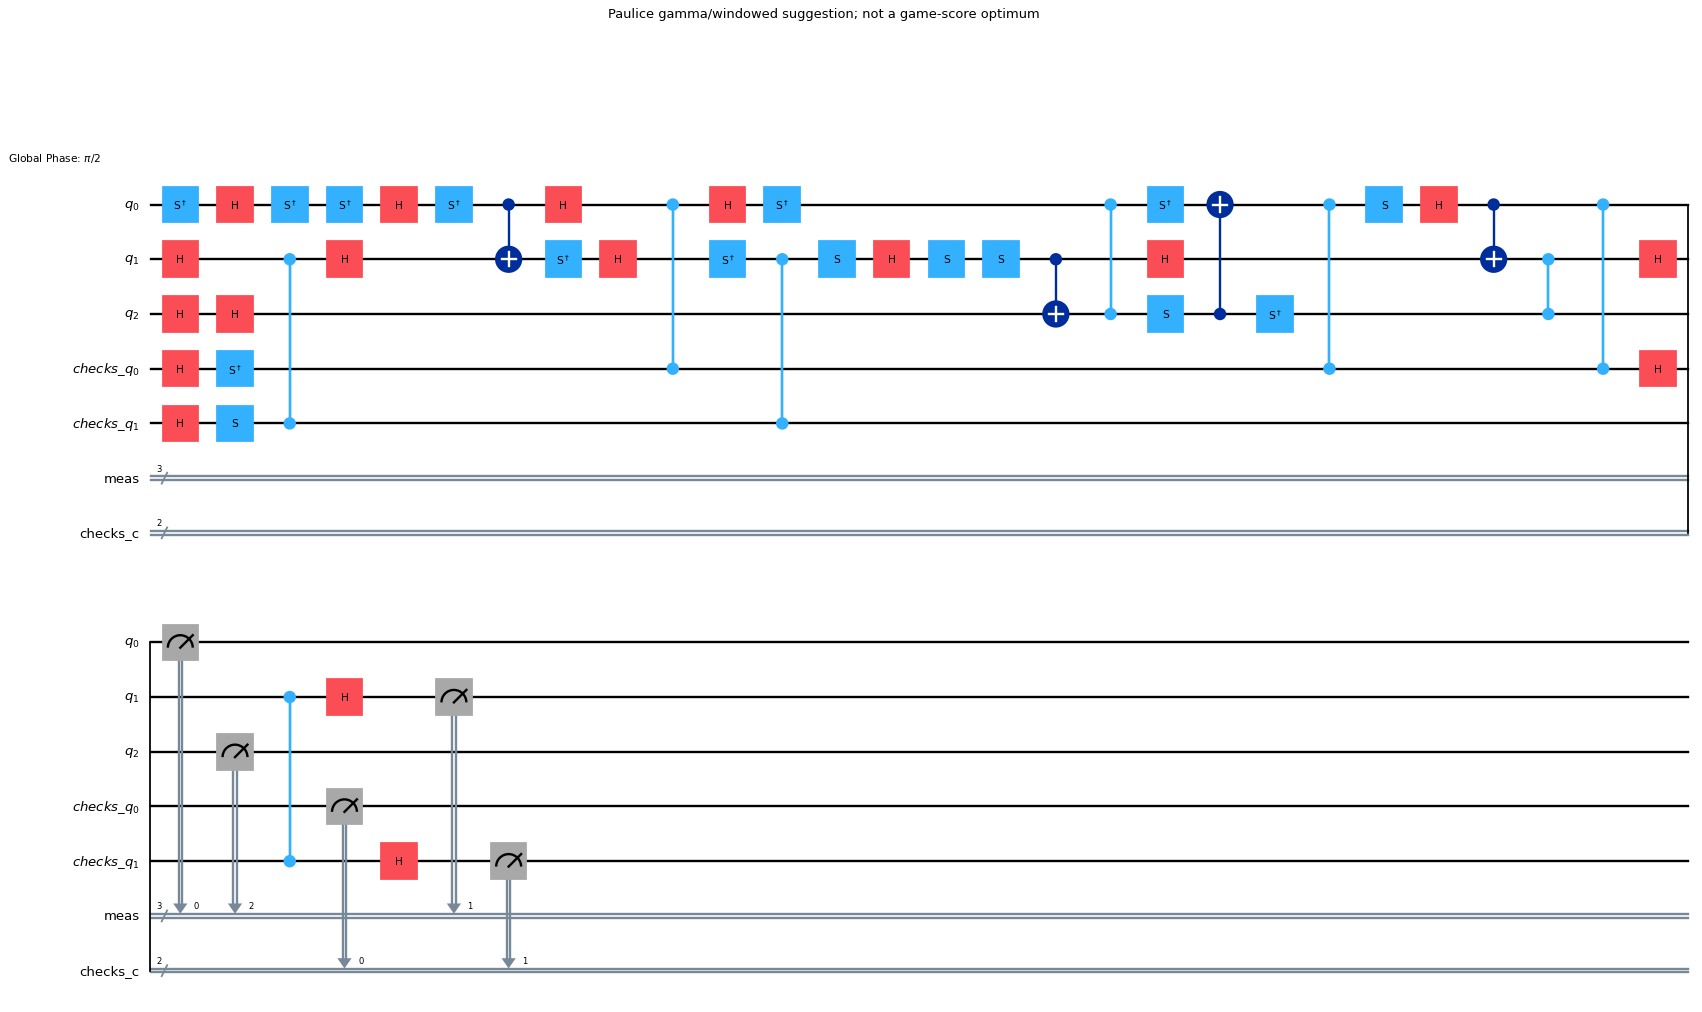

In [14]:
design = QuantumCircuit(3)
design.h(2)
design.x(0)
design.cx(0, 1)
design.h(2)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 2, 0.92, 0.66
hotspot_column, relaxation_us = 2, 82.0
actual = lab.missions.get_level(4)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XXX', 0, 15, 2),
 'misplaced': ('IIX', 0, 1, 1),
 'overchecked': ('IIX', 0, 15, 1),
 'reasonable': ('IXI', 1, 3, 1),
 'tooSmall': ('IZI', 2, 3, 1)}
drafts = {name:shell(4, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(4)
search = search_now(4)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[4] = lab.main_level(4, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main5"></a>
## 4.5. Main Level 5

A longer Clifford path spreads the transported support. The assisted closer is recomputed from the authored opening and actual interval; no notebook-specific closing rule is supplied.


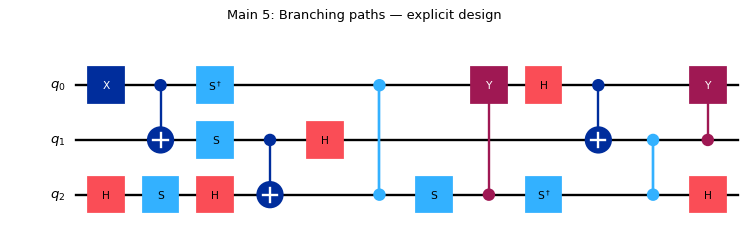

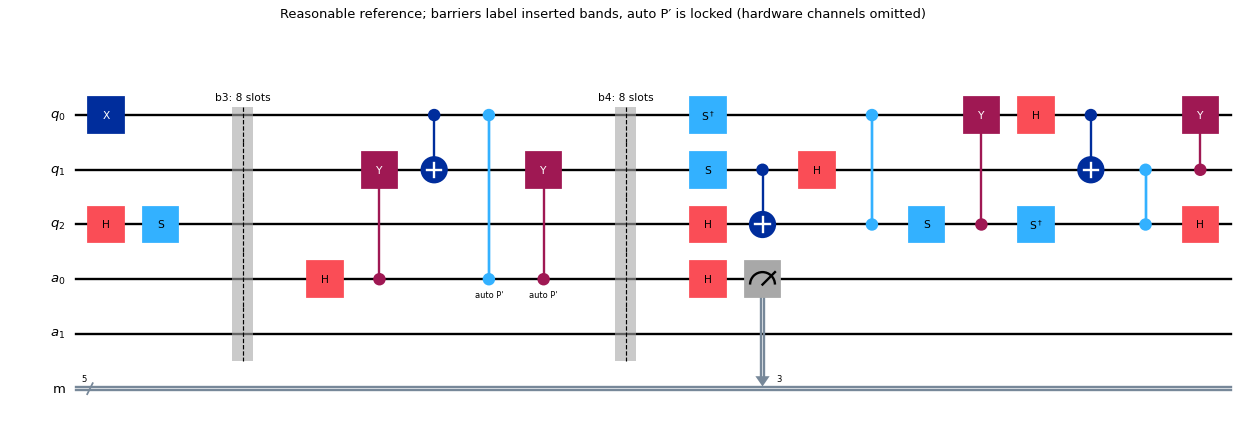

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.424433,1,0.424433,0.424433,0.9,0.66,0,False,False,0,0
everywhere,0.392453,0.810364,0.353367,0.31803,0.9,0.66,0,True,False,2,12
reasonable,0.79184,0.80225,0.705837,0.635253,0.9,0.66,0,True,True,1,3
optimal,0.800864,0.810745,0.721441,0.649297,0.9,0.66,0,True,True,1,2
misplaced,0.417693,0.973652,0.417693,0.406688,0.9,0.66,0,True,False,1,2
tooSmall,0.916722,0.43816,0.446301,0.401671,0.9,0.66,0,True,False,1,3
overchecked,0.77258,0.784955,0.673823,0.606441,0.9,0.66,0,True,True,1,4


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 18 Depth: 11
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 3, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 84.0}
Inserted editable bands: {"0": 4, "18": 8, "3": 8, "4": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b3s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cz", "wires": [3, 0], "location": "auto-0-0", "locked": true}, {"operator": "cy", "wires": [3, 1], "location": "auto-0-1", "locked": true}]
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (3, 4) live search seconds: 19.914
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.15439,[],[],0,19
1,1,1.08887,[0],"[[2, 3]]",1,27
2,2,1.07443,"[0, 1]","[[2, 3], [1, 4]]",2,30


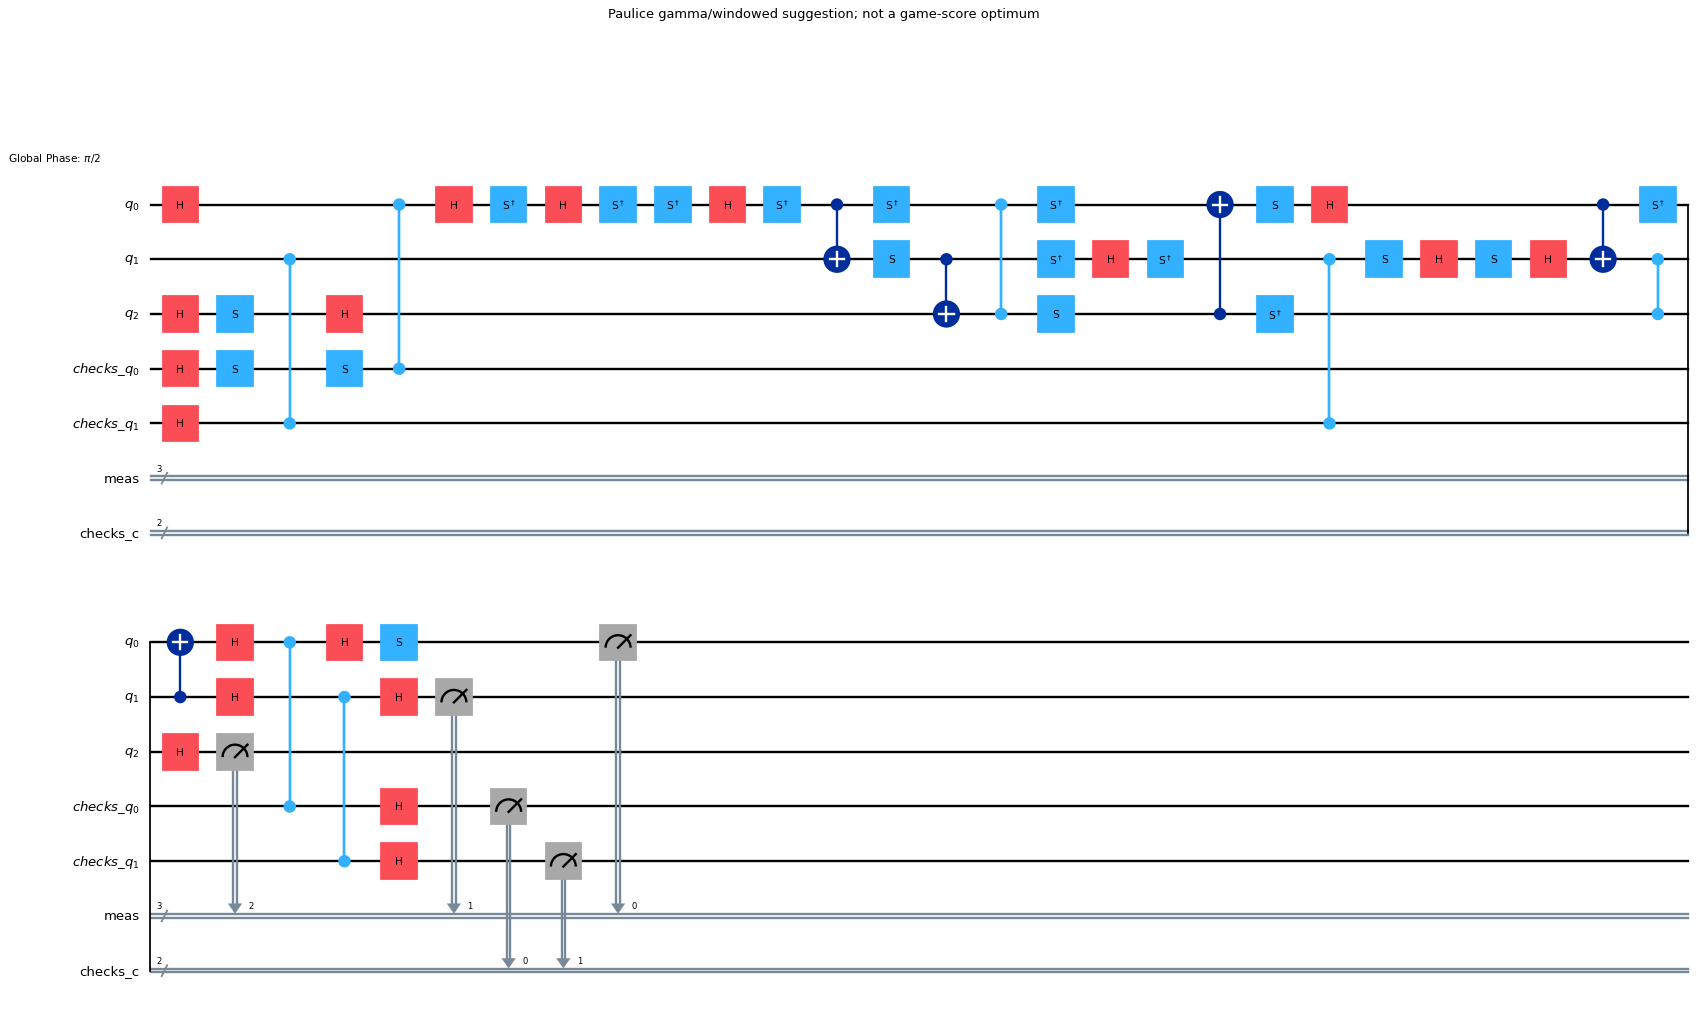

In [15]:
design = QuantumCircuit(3)
design.h(2)
design.s(2)
design.x(0)
design.cx(0, 1)
design.h(2)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
design.h(2)
design.cy(1, 0)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 2, 0.9, 0.66
hotspot_column, relaxation_us = 3, 84.0
actual = lab.missions.get_level(5)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XXX', 0, 18, 2),
 'misplaced': ('IIX', 0, 1, 1),
 'overchecked': ('ZIY', 0, 18, 1),
 'reasonable': ('IYI', 3, 4, 1),
 'tooSmall': ('IZI', 3, 4, 1)}
drafts = {name:shell(5, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(5)
search = search_now(5)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[5] = lab.main_level(5, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main6"></a>
## 4.6. Main Level 6

The larger Clifford workload adds noisy opportunities without changing the score definition. Compare the reasonable interval with a blanket strategy and the freshly searched finite-family winner.


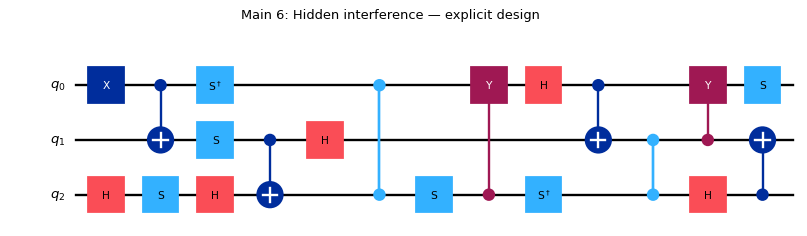

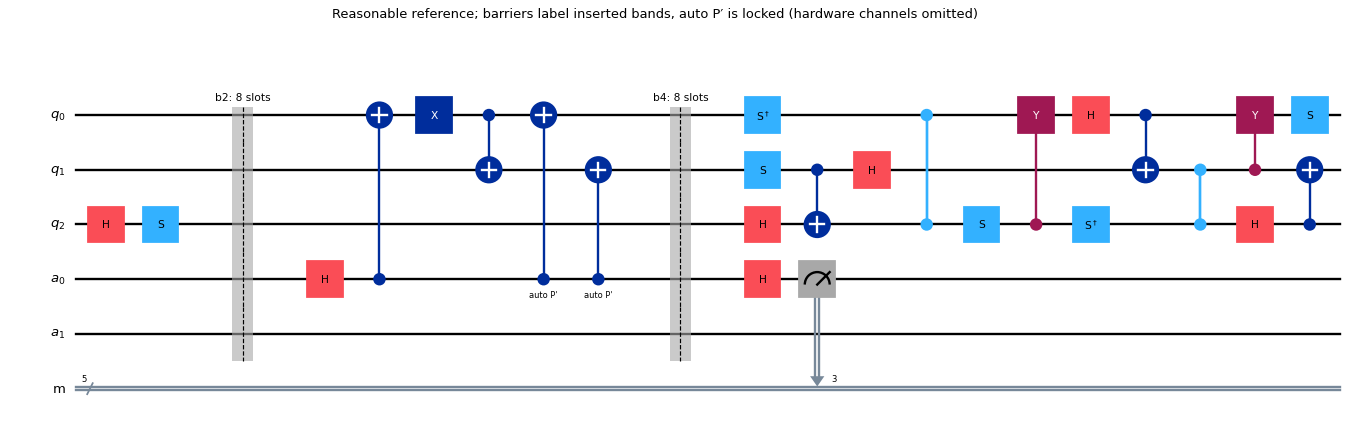

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.414982,1,0.414982,0.414982,0.87,0.67,0,False,False,0,0
everywhere,0.385864,0.833232,0.369557,0.321514,0.87,0.67,0,True,False,2,10
reasonable,0.783827,0.799362,0.720186,0.626562,0.87,0.67,0,True,True,1,3
optimal,0.795639,0.807653,0.738621,0.6426,0.87,0.67,0,True,True,1,2
misplaced,0.408395,0.973652,0.408395,0.397634,0.87,0.67,0,True,False,1,2
tooSmall,0.912869,0.430304,0.451507,0.392811,0.87,0.67,0,True,False,1,3
overchecked,0.767688,0.780348,0.688579,0.599064,0.87,0.67,0,True,True,1,4


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 20 Depth: 12
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 3, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 86.0}
Inserted editable bands: {"0": 4, "2": 8, "20": 8, "4": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b2s1", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 0], "location": "auto-0-0", "locked": true}, {"operator": "cx", "wires": [3, 1], "location": "auto-0-1", "locked": true}]
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (3, 4) live search seconds: 23.822
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.17775,[],[],0,20
1,1,1.09617,[0],"[[2, 3]]",1,28
2,2,1.07802,"[0, 1]","[[2, 3], [1, 2, 4]]",2,31


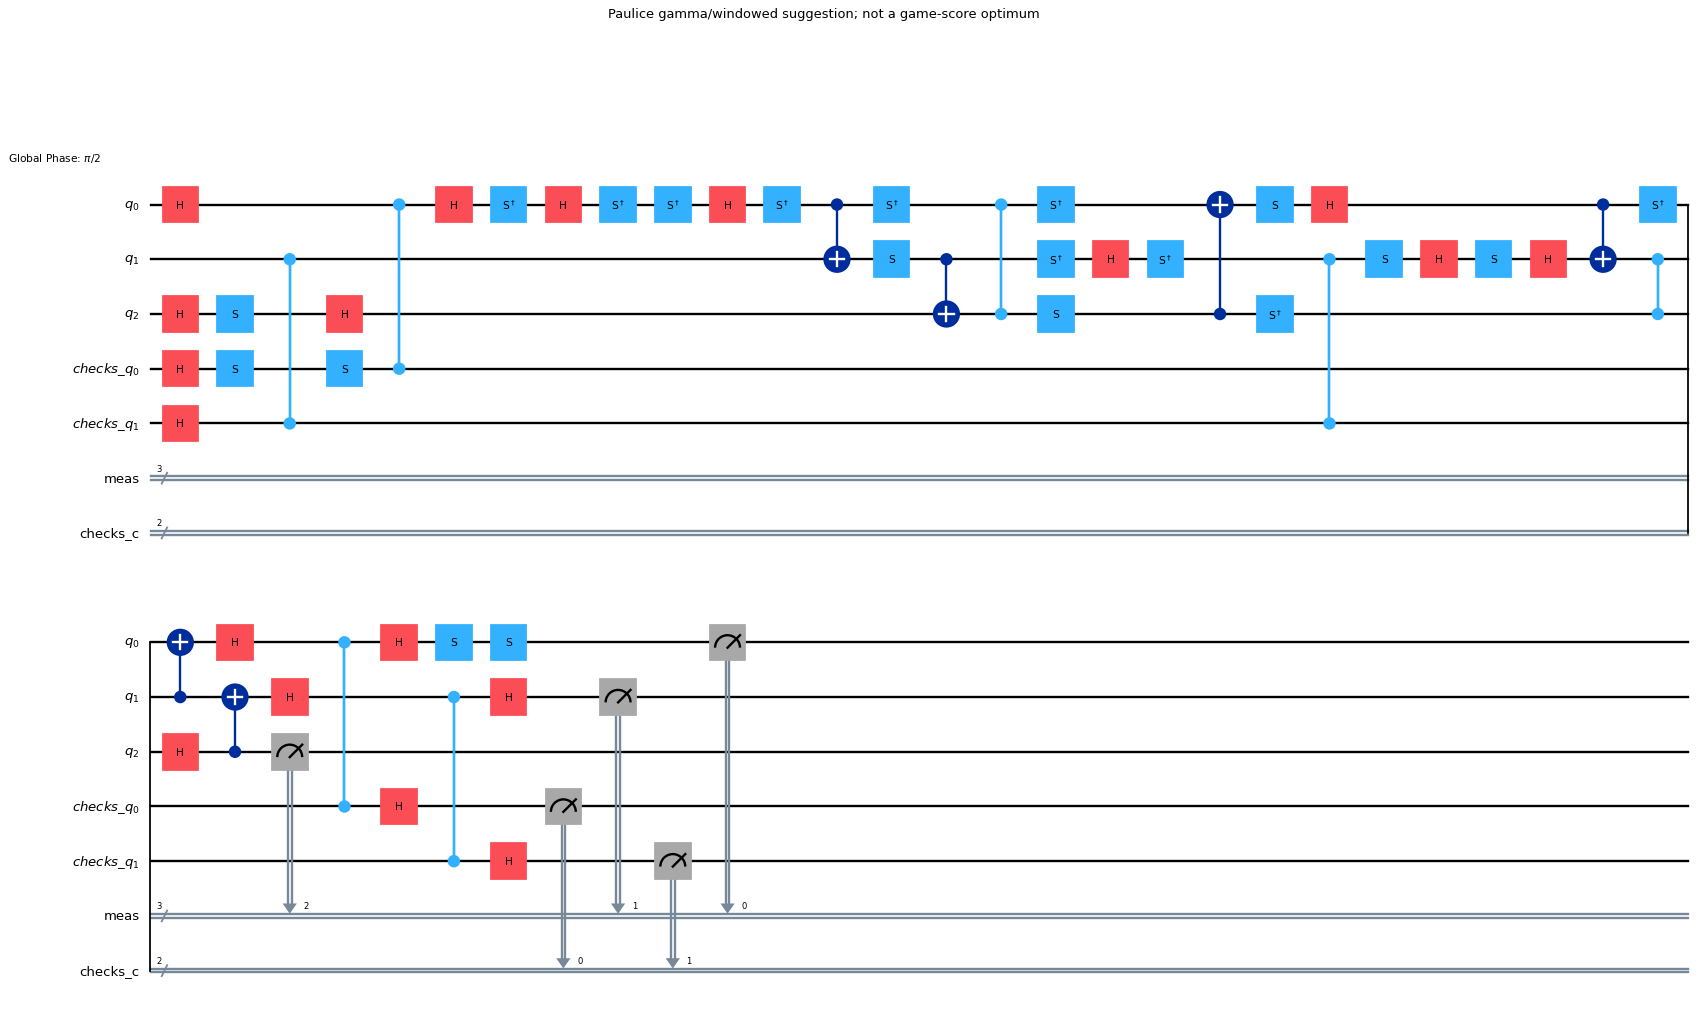

In [16]:
design = QuantumCircuit(3)
design.h(2)
design.s(2)
design.x(0)
design.cx(0, 1)
design.h(2)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
design.h(2)
design.cy(1, 0)
design.s(0)
design.cx(2, 1)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 2, 0.87, 0.67
hotspot_column, relaxation_us = 3, 86.0
actual = lab.missions.get_level(6)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XXX', 0, 20, 2),
 'misplaced': ('IIX', 0, 1, 1),
 'overchecked': ('YIX', 0, 20, 1),
 'reasonable': ('IIX', 2, 4, 1),
 'tooSmall': ('IZI', 3, 4, 1)}
drafts = {name:shell(6, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(6)
search = search_now(6)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[6] = lab.main_level(6, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main7"></a>
## 4.7. Main Level 7

The largest Clifford mission permits more helpers. The full-isometry validator must accept simultaneous loops; native Paulice gamma remains distinct from the exact game-score search.


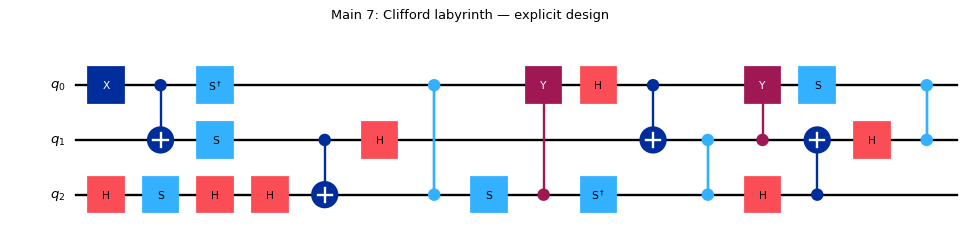

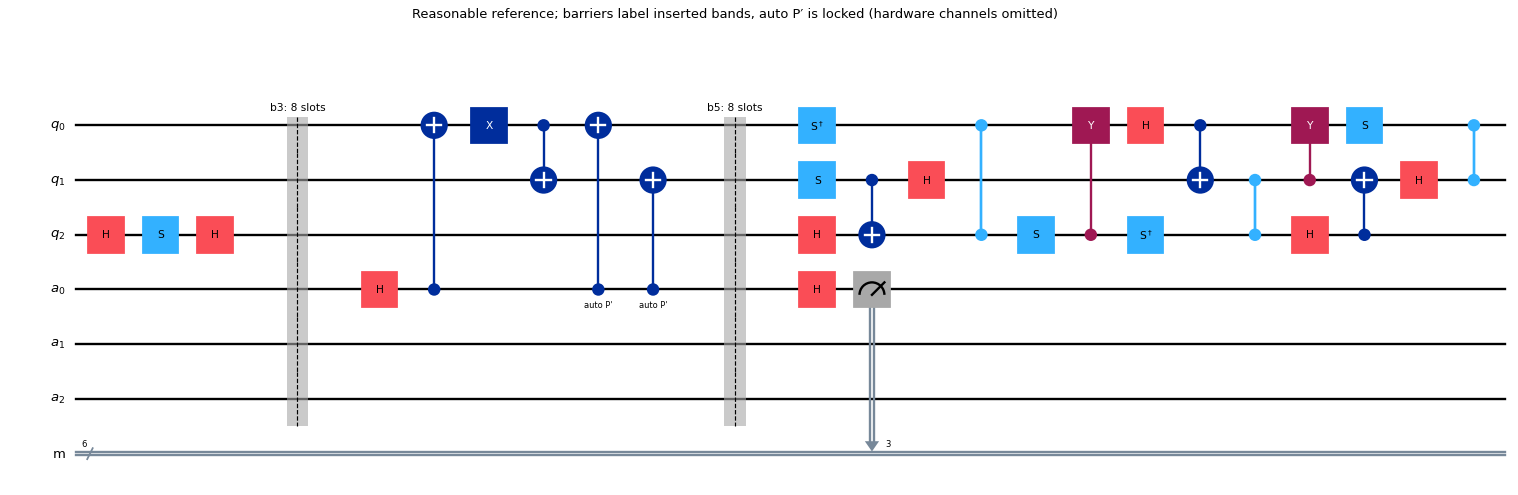

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.405382,1,0.405382,0.405382,0.86,0.67,0,False,False,0,0
everywhere,0.3668,0.752976,0.321153,0.276192,0.86,0.67,0,True,False,3,15
reasonable,0.777988,0.796235,0.720304,0.619462,0.86,0.67,0,True,True,1,3
optimal,0.789774,0.804439,0.73875,0.635325,0.86,0.67,0,True,True,1,2
misplaced,0.398953,0.973652,0.398953,0.388441,0.86,0.67,0,True,False,1,2
tooSmall,0.907323,0.42291,0.446181,0.383716,0.86,0.67,0,True,False,1,3
overchecked,0.761217,0.776782,0.687558,0.5913,0.86,0.67,0,True,True,1,4


Data: 3 Fixed helpers: 3 T/Tdg: 0 Payload gates: 23 Depth: 15
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 4, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 88.0}
Inserted editable bands: {"0": 4, "23": 8, "3": 8, "5": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b3s1", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 0], "location": "auto-0-0", "locked": true}, {"operator": "cx", "wires": [3, 1], "location": "auto-0-1", "locked": true}]
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (4, 5) live search seconds: 23.998
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


stage,checks,nativeGamma,targets,support,addedAncillas,depth
0,0,1.20963,[],[],0,21
1,1,1.11091,[0],"[[1, 2, 3]]",1,27
2,2,1.07622,"[0, 1]","[[1, 2, 3], [1, 2, 4]]",2,30
3,3,1.06372,"[0, 1, 2]","[[1, 2, 3], [1, 2, 4], [5]]",3,40


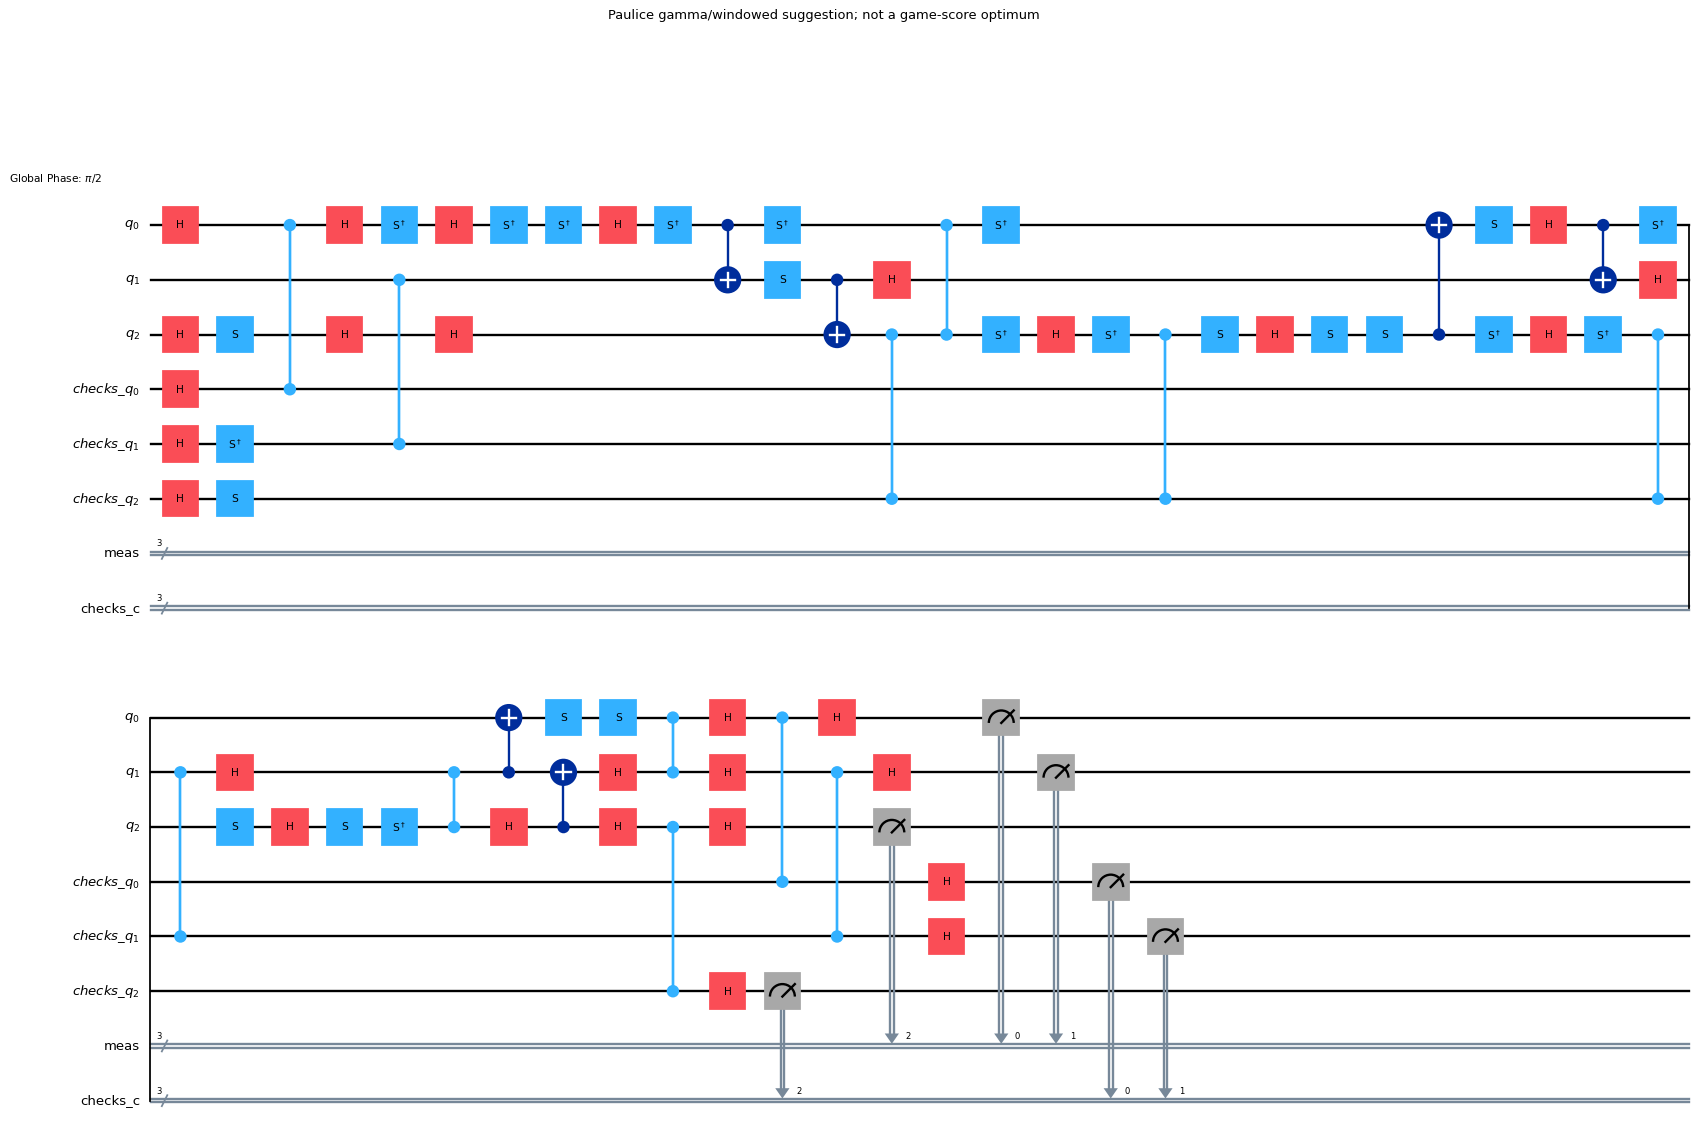

In [17]:
design = QuantumCircuit(3)
design.h(2)
design.s(2)
design.h(2)
design.x(0)
design.cx(0, 1)
design.h(2)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
design.h(2)
design.cy(1, 0)
design.s(0)
design.cx(2, 1)
design.h(1)
design.cz(0, 1)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 3, 0.86, 0.67
hotspot_column, relaxation_us = 4, 88.0
actual = lab.missions.get_level(7)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('XXX', 0, 23, 3),
 'misplaced': ('IIX', 0, 1, 1),
 'overchecked': ('ZIX', 0, 23, 1),
 'reasonable': ('IIX', 3, 5, 1),
 'tooSmall': ('IZI', 4, 5, 1)}
drafts = {name:shell(7, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(7)
search = search_now(7)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[7] = lab.main_level(7, design, drafts, search)
SUMMARY.append(row)
native_path = lab.paulice_path(design, targets=list(range(min(helpers, design.num_qubits))), ancilla_limit=helpers)


<a id="main8"></a>
## 4.8. Main Level 8

The first T-doped payload uses an exact Aer density scorer with a statevector ideal. The custom search runs the real optimizer, accepts only I/Z support at T crossings, and every candidate and the winning draft are scored during execution. Paulice is not called on this circuit.


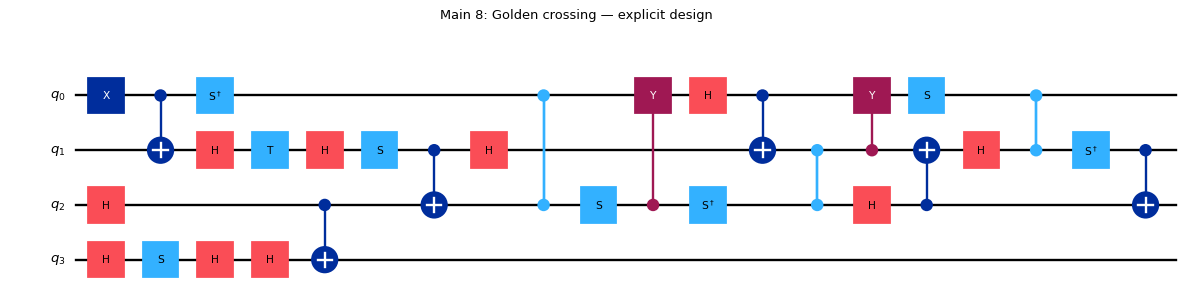

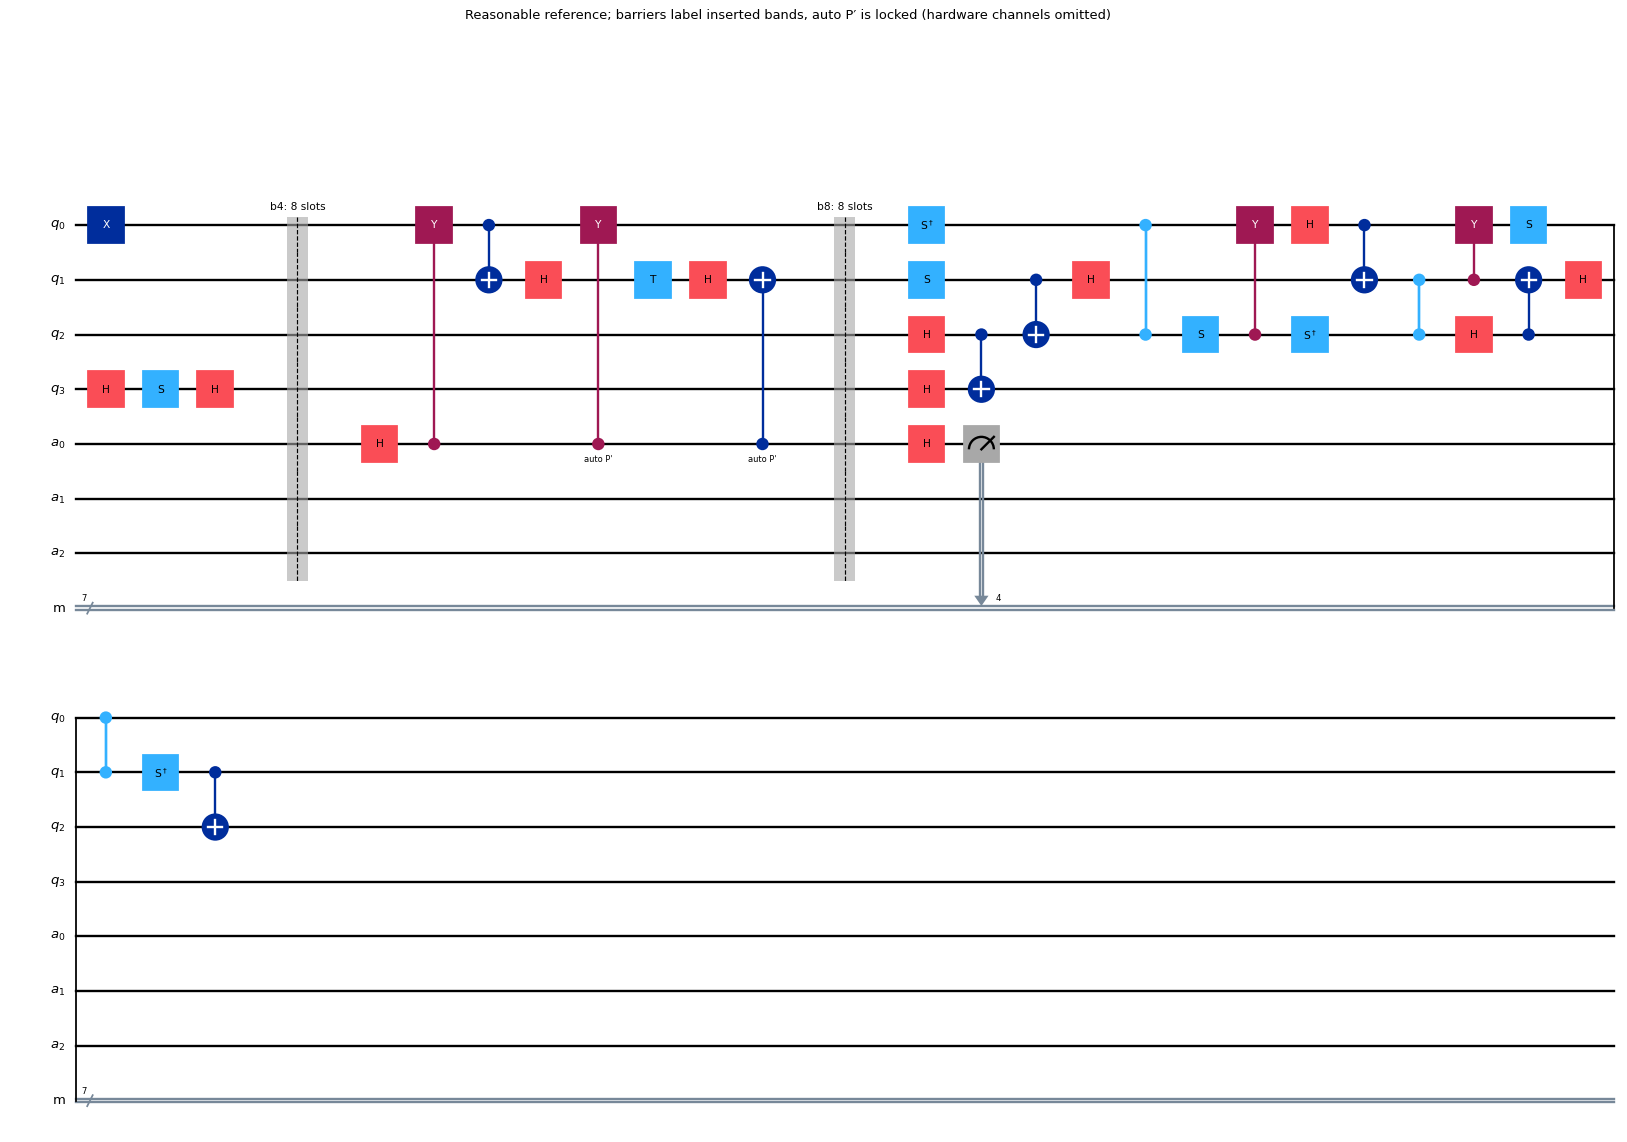

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.390749,1,0.390749,0.390749,0.83,0.67,0,False,False,0,0
everywhere,0.332529,0.637343,0.255343,0.211935,0.83,0.67,0,True,False,3,24
reasonable,0.758841,0.791679,0.723805,0.600758,0.83,0.67,0,True,True,1,3
optimal,0.77056,0.80141,0.744017,0.617534,0.83,0.67,0,True,True,1,2
misplaced,0.384169,0.973652,0.384169,0.374046,0.83,0.67,0,True,False,1,2
tooSmall,0.886592,0.41537,0.443691,0.368263,0.83,0.67,0,True,False,1,3
overchecked,0.744491,0.767636,0.688552,0.571498,0.83,0.67,0,True,True,1,4


Data: 4 Fixed helpers: 3 T/Tdg: 1 Payload gates: 30 Depth: 19
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 4, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 90.0}
Inserted editable bands: {"0": 4, "30": 8, "4": 8, "8": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b4s1", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cy", "wires": [4, 0], "location": "auto-0-0", "locked": true}, {"operator": "cx", "wires": [4, 1], "location": "auto-0-1", "locked": true}]
Search: custom-t-pauli-search candidates: 891 best opening: IIXI interval: (4, 5) live search seconds: 92.312
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; statevector ideal; no Paulice
Custom T-compatib

In [18]:
design = QuantumCircuit(4)
design.h(3)
design.s(3)
design.h(3)
design.x(0)
design.cx(0, 1)
design.h(1)
design.t(1)
design.h(1)
design.h(2)
design.h(3)
design.cx(2, 3)
design.s(1)
design.cx(1, 2)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
design.h(2)
design.cy(1, 0)
design.s(0)
design.cx(2, 1)
design.h(1)
design.cz(0, 1)
design.sdg(1)
design.cx(1, 2)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 3, 0.83, 0.67
hotspot_column, relaxation_us = 4, 90.0
actual = lab.missions.get_level(8)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('YXXY', 0, 30, 3),
 'misplaced': ('IIIX', 0, 1, 1),
 'overchecked': ('XIIX', 0, 30, 1),
 'reasonable': ('IIIY', 4, 8, 1),
 'tooSmall': ('IIZI', 4, 5, 1)}
drafts = {name:shell(8, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(8)
search = search_now(8)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[8] = lab.main_level(8, design, drafts, search)
SUMMARY.append(row)
print("Custom T-compatible search: each valid Pauli opening is propagated gate by gate.")
print("I/Z is required at every T/Tdg crossing; X/Y branches are rejected before scoring.")
print("This search does not call Paulice. The winner may use X/Y outside a T crossing.")


<a id="main9"></a>
## 4.9. Main Level 9

Additional T/Tdg barriers narrow valid Pauli support and locations. The same T-capable scorer and custom search are used; compare the freshly searched best-found interval with a reasonable, lower-scoring valid solution.


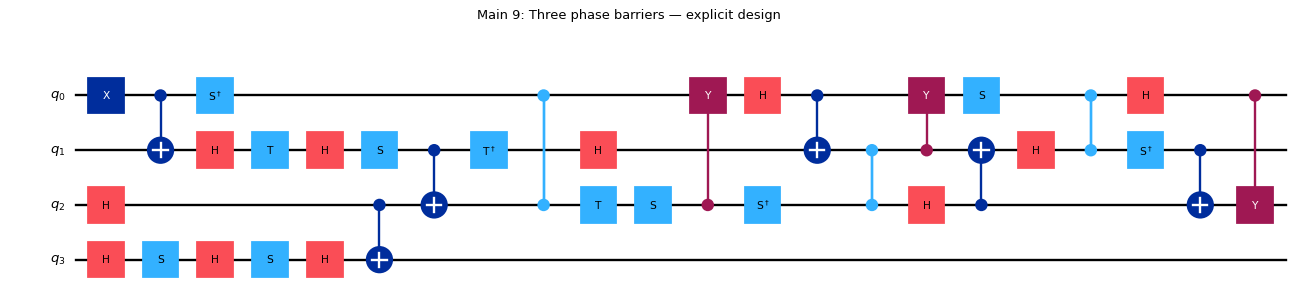

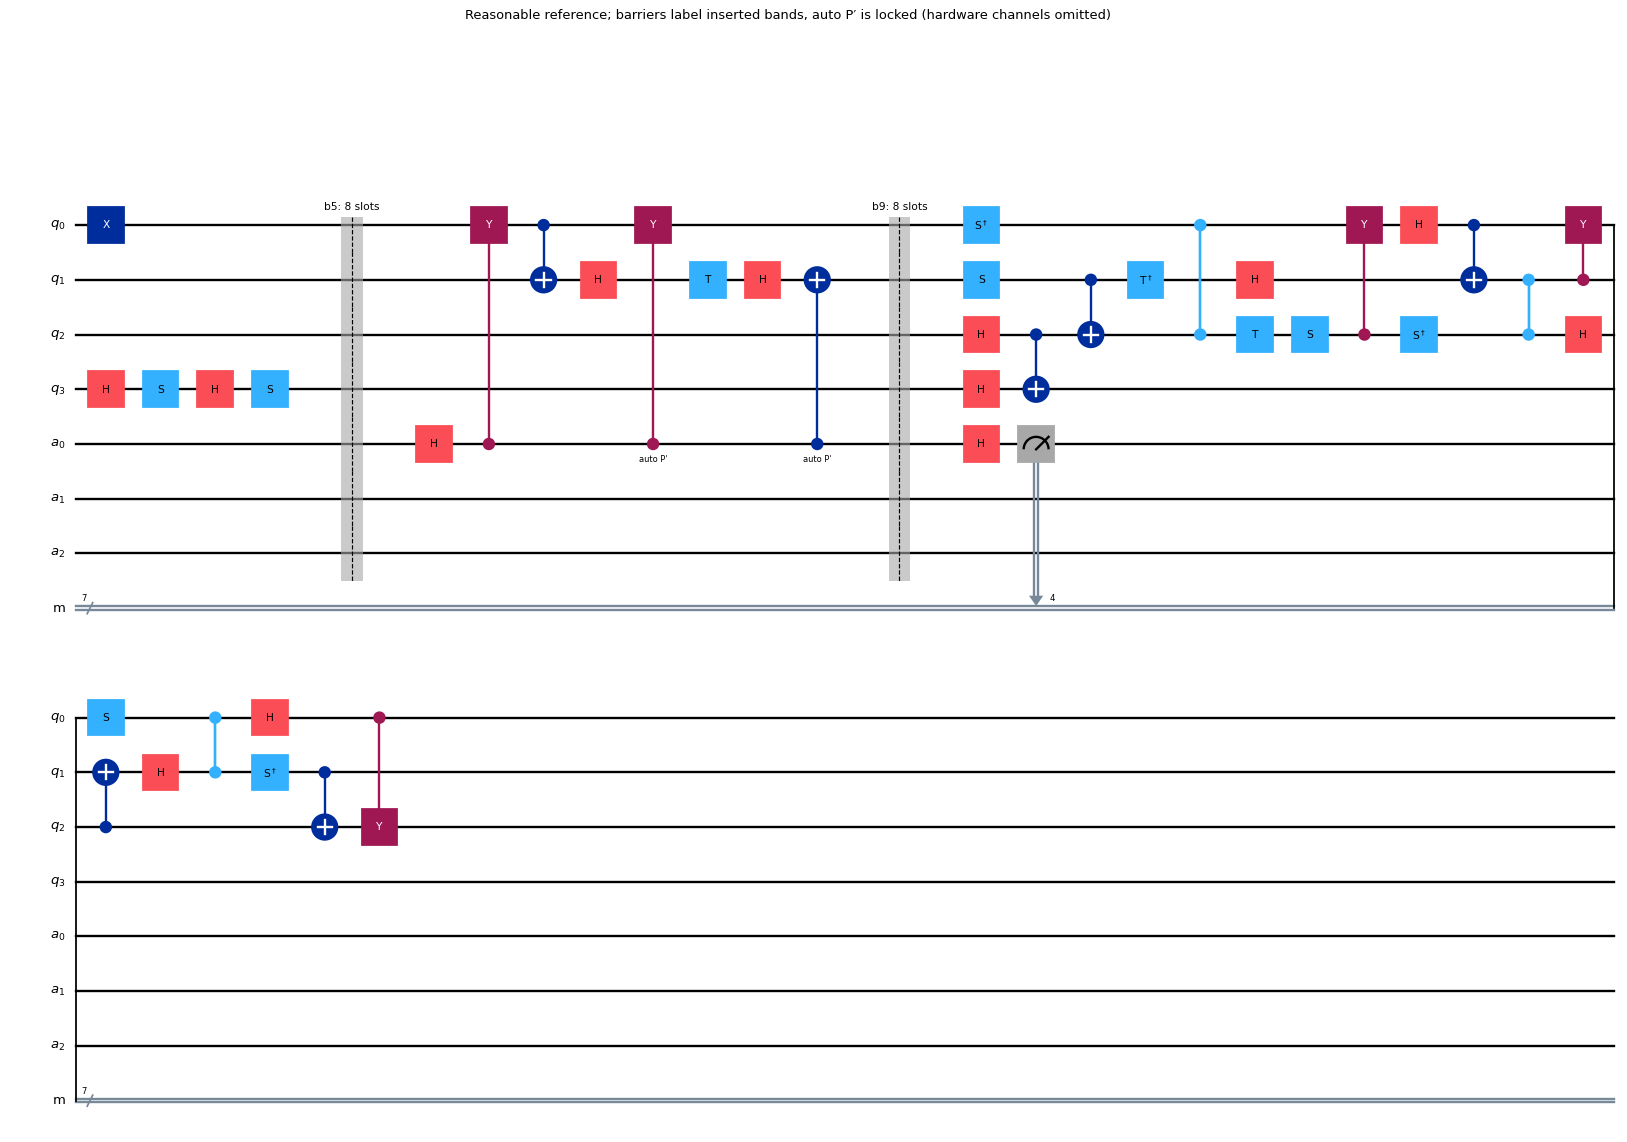

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.381199,1,0.381199,0.381199,0.82,0.67,0,False,False,0,0
everywhere,0.322992,0.632148,0.248999,0.204179,0.82,0.67,0,True,False,3,24
reasonable,0.75184,0.788632,0.723079,0.592925,0.82,0.67,0,True,True,1,3
optimal,0.763399,0.798262,0.743161,0.609392,0.82,0.67,0,True,True,1,2
misplaced,0.374792,0.973652,0.374792,0.364916,0.82,0.67,0,True,False,1,2
tooSmall,0.879308,0.4083,0.43783,0.359021,0.82,0.67,0,True,False,1,3
overchecked,0.742881,0.78091,0.707467,0.580123,0.82,0.67,0,True,True,1,4


Data: 4 Fixed helpers: 3 T/Tdg: 3 Payload gates: 35 Depth: 21
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 5, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 92.0}
Inserted editable bands: {"0": 4, "35": 8, "5": 8, "9": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b5s1", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cy", "wires": [4, 0], "location": "auto-0-0", "locked": true}, {"operator": "cx", "wires": [4, 1], "location": "auto-0-1", "locked": true}]
Search: custom-t-pauli-search candidates: 699 best opening: IIXI interval: (5, 6) live search seconds: 79.761
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; statevector ideal; no Paulice
Custom T-compatib

In [19]:
design = QuantumCircuit(4)
design.h(3)
design.s(3)
design.h(3)
design.s(3)
design.x(0)
design.cx(0, 1)
design.h(1)
design.t(1)
design.h(1)
design.h(2)
design.h(3)
design.cx(2, 3)
design.s(1)
design.cx(1, 2)
design.tdg(1)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.t(2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
design.h(2)
design.cy(1, 0)
design.s(0)
design.cx(2, 1)
design.h(1)
design.cz(0, 1)
design.sdg(1)
design.cx(1, 2)
design.h(0)
design.cy(0, 2)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 3, 0.82, 0.67
hotspot_column, relaxation_us = 5, 92.0
actual = lab.missions.get_level(9)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('YXXY', 0, 35, 3),
 'misplaced': ('IIIX', 0, 1, 1),
 'overchecked': ('YIXI', 5, 9, 1),
 'reasonable': ('IIIY', 5, 9, 1),
 'tooSmall': ('IIZI', 5, 6, 1)}
drafts = {name:shell(9, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(9)
search = search_now(9)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[9] = lab.main_level(9, design, drafts, search)
SUMMARY.append(row)
print("Custom T-compatible search: each valid Pauli opening is propagated gate by gate.")
print("I/Z is required at every T/Tdg crossing; X/Y branches are rejected before scoring.")
print("This search does not call Paulice. The winner may use X/Y outside a T crossing.")


<a id="main10"></a>
## 4.10. Main Level 10

The largest T-doped mission remains within the physical-wire bound. All baseline/blanket/reasonable/best-found records are run repeatedly, including the ordinary auto-P′ logic. The best-found label is bounded by the declared search family, not a universal optimizer claim.


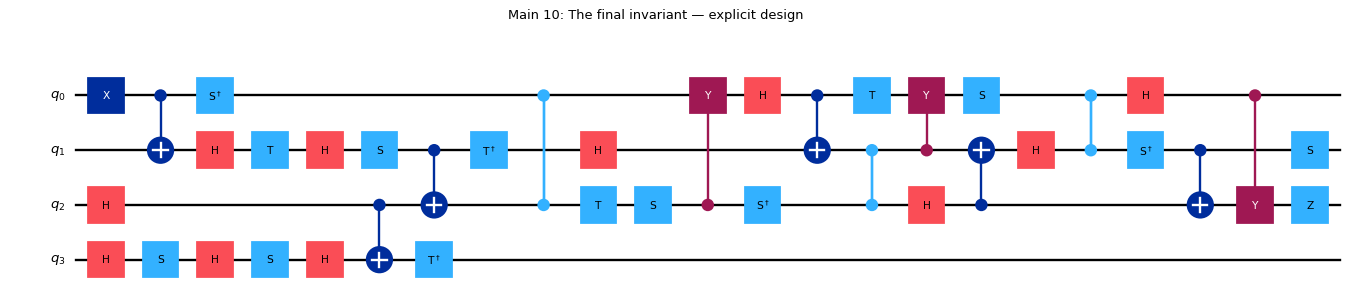

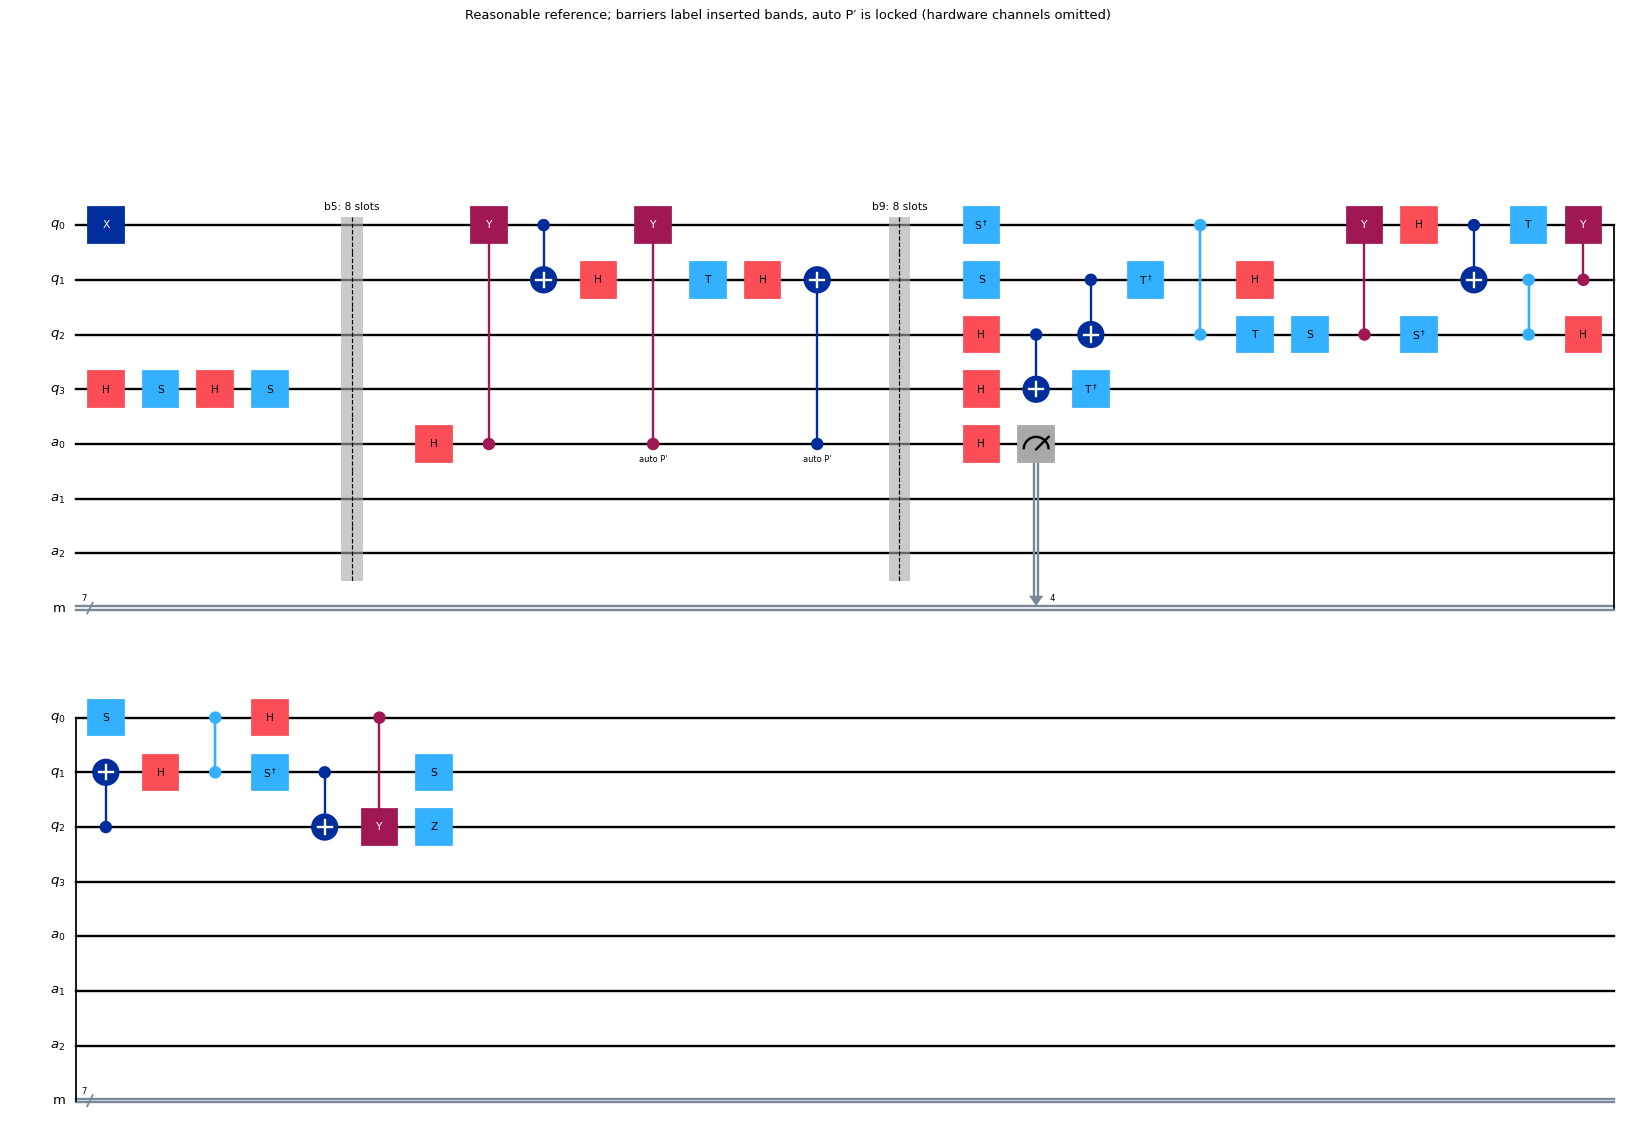

strategy,fidelity,kept,score,correct_shot_yield,minimumKept,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.371958,1,0.371958,0.371958,0.8,0.67,0,False,False,0,0
everywhere,0.327538,0.663749,0.271754,0.217403,0.8,0.67,0,True,False,3,21
reasonable,0.744778,0.78576,0.731521,0.585217,0.8,0.67,0,True,True,1,3
optimal,0.756297,0.795294,0.751848,0.601479,0.8,0.67,0,True,True,1,2
misplaced,0.365711,0.973652,0.365711,0.356075,0.8,0.67,0,True,False,1,2
tooSmall,0.872818,0.401062,0.437568,0.350054,0.8,0.67,0,True,False,1,3
overchecked,0.73589,0.778115,0.715758,0.572607,0.8,0.67,0,True,True,1,4


Data: 4 Fixed helpers: 3 T/Tdg: 5 Payload gates: 39 Depth: 22
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 5, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 94.0}
Inserted editable bands: {"0": 4, "39": 8, "5": 8, "9": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b5s1", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cy", "wires": [4, 0], "location": "auto-0-0", "locked": true}, {"operator": "cx", "wires": [4, 1], "location": "auto-0-1", "locked": true}]
Search: custom-t-pauli-search candidates: 651 best opening: IIXI interval: (5, 6) live search seconds: 78.406
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; statevector ideal; no Paulice
Custom T-compatib

In [20]:
design = QuantumCircuit(4)
design.h(3)
design.s(3)
design.h(3)
design.s(3)
design.x(0)
design.cx(0, 1)
design.h(1)
design.t(1)
design.h(1)
design.h(2)
design.h(3)
design.cx(2, 3)
design.s(1)
design.cx(1, 2)
design.tdg(1)
design.sdg(0)
design.h(1)
design.cz(0, 2)
design.t(2)
design.s(2)
design.cy(2, 0)
design.h(0)
design.tdg(3)
design.cx(0, 1)
design.sdg(2)
design.cz(1, 2)
design.t(0)
design.h(2)
design.cy(1, 0)
design.s(0)
design.cx(2, 1)
design.h(1)
design.cz(0, 1)
design.sdg(1)
design.cx(1, 2)
design.h(0)
design.cy(0, 2)
design.z(2)
design.s(1)
# Explicit design parameters; compare with the deployed fixture before scoring.
helpers, minimum_kept, target = 3, 0.8, 0.67
hotspot_column, relaxation_us = 5, 94.0
actual = lab.missions.get_level(10)
lab.assert_same_circuit(design, lab.missions.qc_for(lab.missions.payload(actual), design.num_qubits))
assert (actual["ancillas"], actual["minimumKept"], actual["targetScore"]) == (helpers, minimum_kept, target)
assert actual["noise"] == dict(hotspotColumn=hotspot_column, qubit=1, timeUs=relaxation_us,
    t1Us=100., t2Us=200., checkStrength=.025, hardware=mission_hardware)
# Pauli labels are big-endian; boundaries count serialized payload instructions.
trials = {'everywhere': ('ZXXY', 0, 39, 3),
 'misplaced': ('IIIX', 0, 1, 1),
 'overchecked': ('YIXI', 5, 9, 1),
 'reasonable': ('IIIY', 5, 9, 1),
 'tooSmall': ('IIZI', 5, 6, 1)}
drafts = {name:shell(10, label, start, end, helpers=count)
          for name,(label,start,end,count) in trials.items()}
drafts["baseline"] = empty(10)
search = search_now(10)
drafts["optimal"] = search["result"]["best"]["draft"]
row, STRATEGY_ROWS[10] = lab.main_level(10, design, drafts, search)
SUMMARY.append(row)
print("Custom T-compatible search: each valid Pauli opening is propagated gate by gate.")
print("I/Z is required at every T/Tdg crossing; X/Y branches are rejected before scoring.")
print("This search does not call Paulice. The winner may use X/Y outside a T crossing.")


<a id="cross-level"></a>
## Across levels

FS1-5 complete through experiments and learning checks, so they have no numeric target. Compare score and retention for the scored levels. Width, depth and T count are circuit-size indicators, not measured human difficulty.


level,data,ancillas,tCount,minimumKept,baseline,everywhere,reasonable,optimal,target,spread,completion,demonstratedFidelity
FS1,1,0,0,—,—,—,—,—,—,—,Run experiment and correctly answer all three MCQs.,0
FS2,1,method-dependent,0,—,—,—,—,—,—,—,Try all three methods on a valid authored circuit.,—
FS3,1,1,0,—,—,—,—,—,—,—,Complete the guided physical check and knowledge questions.,—
FS4,2,1,0,—,—,—,—,—,—,—,Complete the guided physical check and knowledge questions.,—
FS5,1,1,1,—,—,—,—,—,—,—,Complete the guided physical check and knowledge questions.,—
FS6,2,1,0,0.99,0.494132,0.461596,0.674885,0.69305,0.62,0,"Pass score threshold, review real Paulice and reference comparison.",—
Main1,2,1,0,0.99,0.466665,0.440177,0.682206,0.6885,0.63,0,Score target with a valid invariant,—
Main2,3,1,0,0.97,0.455944,0.418645,0.692925,0.69316,0.64,0,Score target with a valid invariant,—
Main3,3,2,0,0.94,0.445385,0.357518,0.707868,0.708107,0.65,0,Score target with a valid invariant,—
Main4,3,2,0,0.92,0.436066,0.360783,0.716577,0.716818,0.66,0,Score target with a valid invariant,—


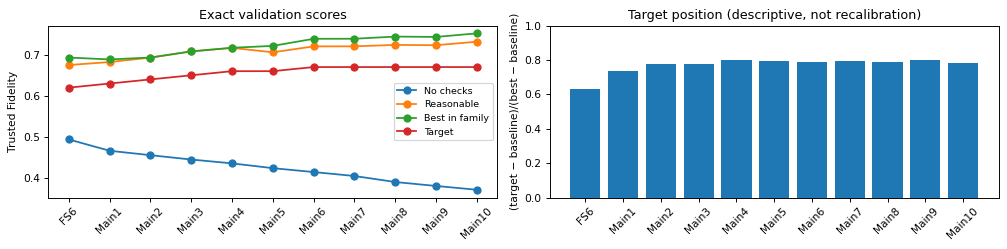

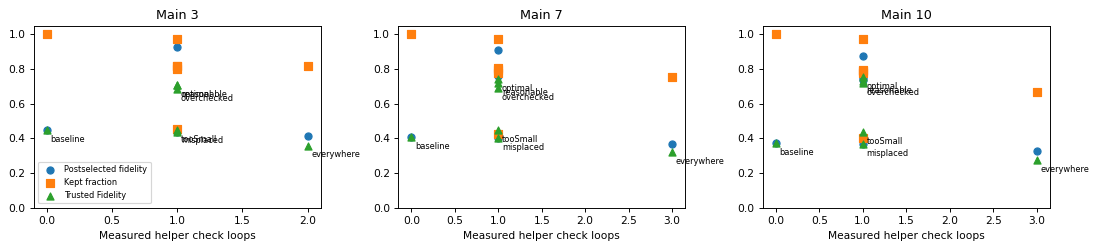

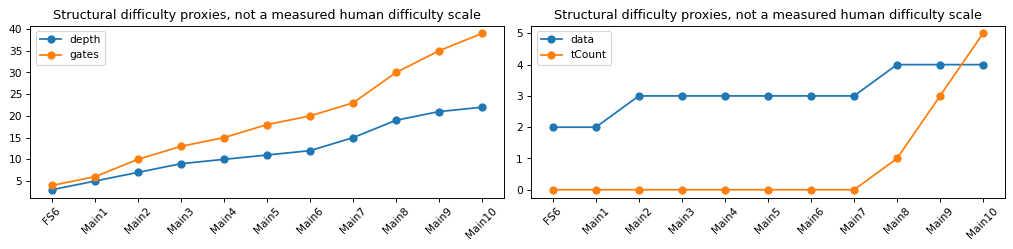

All displayed scored rows will be checked against full-precision reference JSON and the rounded validation document.


In [21]:
DIFFICULTY = lab.cross_level(SUMMARY, STRATEGY_ROWS)
from scripts.run_notebook import validate_manifest
print("All displayed scored rows will be checked against full-precision reference JSON and the rounded validation document.")

<a id="t-validation"></a>
## T scorer and timing

Run the existing agreement, density-matrix and forbidden-crossing checks. Timings use all available wires and uncached local runs; they are not cloud cold-start guarantees.


In [22]:
from scripts.validate_t_scoring import verify_t_scoring
T_CHECK = verify_t_scoring()
table(T_CHECK["cliffordAgreement"])
table([dict(smallCliffordDensityDifference=T_CHECK["smallCliffordDensityDifference"])])
table([dict(level=row["level"], physicalQubits=row["physicalQubits"], engine=row["engine"],
            noiselessZ=row["noiselessZ"], invalidXYRejected=row["invalidXYRejected"],
            smallTDensityDifference=row["smallTDensityDifference"],
            runSeconds=row["coldRunSeconds"], scoreSpread=row["scoreSpread"])
       for row in T_CHECK["tLevels"]])

level,maxMetricDifference
1,2.22045e-16
2,2.22045e-16
3,5.55112e-16
4,4.44089e-16
5,5.55112e-16
6,6.66134e-16
7,9.99201e-16


smallCliffordDensityDifference
3.33067e-16


level,physicalQubits,engine,noiselessZ,invalidXYRejected,smallTDensityDifference,runSeconds,scoreSpread
8,7,Aer density_matrix; statevector ideal; custom I/Z-at-T placement search,"{""fidelity"": 1.0, ""retention"": 1.0, ""score"": 1.0, ""correct_shot_yield"": 1.0}",True,2.22045e-16,"[0.19760799998766743, 0.267060100013623, 0.24353470001369715]",0
9,7,Aer density_matrix; statevector ideal; custom I/Z-at-T placement search,"{""fidelity"": 1.0, ""retention"": 1.0, ""score"": 1.0, ""correct_shot_yield"": 1.0}",True,2.22045e-16,"[0.4803461999981664, 0.30021749998559244, 0.2977328000124544]",0
10,7,Aer density_matrix; statevector ideal; custom I/Z-at-T placement search,"{""fidelity"": 1.0, ""retention"": 1.0, ""score"": 1.0, ""correct_shot_yield"": 1.0}",True,2.22045e-16,"[0.283609299978707, 0.2969730000186246, 0.25648549999459647]",0


<a id="reproducibility"></a>
## Reproduction

The runner checks all 16 summary rows against the reference files and LEVEL_VALIDATION.md, and rejects stale sources or missing executions. Run `scripts/validate_all_levels.py` to check gameplay references. All searches run during this notebook execution; no saved search file is required. Neither command recalibrates levels. Analysis dependencies are pinned separately and excluded from deployment.


In [23]:
PACKAGE_NAMES=["qiskit","qiskit-aer","qiskit-paulice","numpy","scipy","matplotlib","pylatexenc",
               "nbformat","nbclient","nbconvert","ipykernel"]
table([dict(package=name, version=version(name)) for name in PACKAGE_NAMES])
RUNTIME = time.perf_counter()-START
print("Python:",platform.python_version(),"Seed:",SEED,"Sampled diagnostic shots:",SHOTS)
print("Actual analysis seconds (kernel startup excluded):",round(RUNTIME,3))
print("Live finite-family search seconds:", round(sum(r["seconds"] for r in SEARCHES), 3))
print("Execution completed UTC:",datetime.now(timezone.utc).isoformat())
print("No absolute filesystem paths or user names are included in the displayed results.")


PackageNotFoundError: No package metadata was found for nbconvert

In [ ]:
MANIFEST=dict(schemaVersion=1, summary=SUMMARY, seed=SEED, shots=SHOTS,
              runtimeSeconds=RUNTIME, searchSeconds=sum(r["seconds"] for r in SEARCHES),
              tValidationPassed=all(row["invalidXYRejected"] for row in T_CHECK["tLevels"]),
              packages={name:version(name) for name in PACKAGE_NAMES},
              inputs=analysis_inputs())
assert validate_manifest(MANIFEST)==len(SUMMARY)
display(JSON(MANIFEST,expanded=False))


<IPython.core.display.JSON object>